# Potential-gap ranking of the training recipes

> The figures and tables as they are in the thesis working copy of 11 Oct 2026, with the earlier arm labels, come from the copy `phi_gap_trajectories_before.ipynb`, which writes them to `assets/thesis_before/`.

This notebook is the source of the potential-gap results of the thesis. It reads these inputs:

- the phi-gap grid under `assets/results/phi-gap/`, written by `scripts/run_phi_gap_grid.py`;
- the λ sweep under `assets/results/phi-gap/lambda-sweep/`, written by the same script with several `--lam` values (section 8);
- the lm-eval results under `assets/results/eval/`;
- the training loss per step, from the W&B export `assets/results/wandb/11B/wandb_11B_lm_loss.csv` and, for the price-barrier arm, which the export lacks, from its training logs under `logs/`, which also check the export (section 2).

Nothing here re-solves an LP or runs a model. Price recovery lives in `alflb_price_internalization.ipynb` and the collapse races in `collapse_recovery_race.ipynb`. A few numbers the thesis quotes come from elsewhere and are not reproduced here:

- the unit-halving measurement;
- the 64 % concentration of the stress unit, which comes from the probe dumps.

**What the thesis takes from here.** Everything below is written to `assets/thesis/`. Set `THESIS_DIR` to the thesis folder to copy these files into its `figures/` and `tables/` as well.

| file | what it holds |
|---|---|
| `figures/fig_ex_phi_gap_trajectories.pdf` | normalized gap over training |
| `figures/fig_ex_maxvio_trajectories.pdf` | MaxVio over training |
| `figures/fig_ex_gap_parts_trajectories.pdf` | raw gap and round-robin gap (the denominator) over training |
| `figures/fig_ex_throughput.pdf` | expert computation time per arm, one panel per balancing scope (an alternative to the table) |
| `tables/tab_ex_phi_gap_ranking.tex` | rows of the ranking table |
| `tables/tab_ex_phi_gap_ranking_with_loss.tex` | the same rows with the training loss as an extra last column |
| `tables/tab_ex_throughput.tex` | rows of the expert-computation-time table, all arms in one block (F, saving vs Switch, ALF-LB, control) |
| `tables/tab_ex_throughput_by_scope.tex` | the same table in one block per balancing scope (F, saving vs control, saving vs the Switch arm of that scope) |
| `tables/tab_ex_phi_gap_decomposition.tex` | rows of the decomposition table, affinity shortfall and congestion excess |
| `tables/tab_ex_robustness.tex` | rows of the robustness table: step 5500, each asset, the stress unit, all 48 instances |
| `tables/tab_ex_lambda_sweep.tex` | rows of the λ-sweep table, normalized gap / λ |
| `tables/tab_ex_paired.tex` | rows of the paired-comparison table |
| `tables/tab_ex_lm_eval.tex` | rows of the downstream-score table |

The chapters keep their own table environments, headers and captions, and read the rows with `\importrows{...}`. Which entries the rows print in bold (the best value of a column, lowest or highest) is set per table and column in the dict `BEST` of section 1. The numbers the running text quotes are collected in section 12, so they can be checked against the text in one place. The notebook names no table, figure or section numbers of the thesis, since those change; the file names above are the interface.

## Terms, as in the thesis

- **Arm:** one training run with one balancing recipe. There are 14.
- **Asset:** a frozen probe set of 16 sequences of 2048 tokens. There are three: tail, strided and spread.
- **Unit:** one half of an asset, 16,384 tokens. A unit is the batch $B$ of the routing game.
- **Game instance, or instance:** one unit at one MoE layer. At every probe step, an arm's router plays one routing game on it. This gives 3 assets × 2 units × 8 layers = 48 instances, each scored at every probe step. The grid writes one CSV row per instance, step and reference cost.
- **Stress unit:** the code-dense first half (`u0`) of the strided asset. It was declared a stress test before any arm was scored (decision 0049 §5).
- **Primary population:** the other 40 instances.
- **Late window:** the 21 probe steps in [5000, 5500] that every arm probed. This is the learning-rate anneal.
- **Normalized gap:** $(\Phi(p) - \Phi(p^*)) / (\Phi(p^\circ) - \Phi(p^*))$, with $\Phi$ the potential of the reference game, $p$ the realized routing, $p^*$ a potential minimizer and $p^\circ$ the round-robin profile, which ignores affinity but is exactly balanced. It is 0 at the minimizer and 1 at the round-robin profile. The grid works with the negated potential `Phi = A - Cong`, which the minimizer maximizes; the ratio is the same.

## What it shows

Gap values are late-window means. A pair a / b is linear / quadratic reference; a single value is the linear one.

1. **The potential gap separates the recipes, and the balancing arms fall into five groups** (ranking table):
   - the four hard micro-batch arms;
   - the two bias arms, ALF-LB and the price barrier, at about twice the gap of the first group;
   - the two soft micro-batch arms;
   - the three hard global-batch arms;
   - the two soft global-batch arms.

   The control comes last, at 28.5, which is 27 times the quadratic hard arm. The order is the same at step 5500 alone.
2. **The four leading arms cannot be ordered with one seed.** They lie within 3.2 % / 5.2 % of each other, and their order changes with the reference. Under the quadratic reference the softplus barrier moves from 4th to 2nd.
3. **The stress unit orders the leading arms by how steep their cost is**: softplus barrier, quadratic, then the two linear-cost arms. This rests partly on one instance:
   - the barrier beats quadratic hard in only 4 of the 8 instances (3 of 8 under the quadratic reference);
   - its lead comes from layer 3;
   - blended into a 48-instance mean, this one instance would put the barrier first by 1.8 %. Rule 3, declared before scoring, keeps such a reversal out of the headline.
4. **Hard beats soft and micro beats global in every instance of the primary population** and at every late-window step.
   - The steeper (quadratic) cost lowers the gap in all four pairs, but per instance clearly only for two of them.
   - Switch and the hard linear loss, which are the same loss, give 1.0852 against 1.0857 at the micro-batch scope and differ by 3.9 % at the global scope.
   - The price-barrier bias and ALF-LB's sign rule cannot be told apart.
5. **What balance buys, in an idealized expert-parallel model** (expert-computation-time table and figure, one block per balancing scope):
   - every balanced arm needs 35–74 % less expert computation time than the control;
   - at the micro-batch scope, quadratic hard needs 4 % less than Switch; at the global-batch scope, quadratic hard needs 17 % less than Switch (global), and the two bias arms 35–36 % less;
   - across the scopes, quadratic hard needs 18 % less than ALF-LB, a comparison that the probe units tilt toward the micro-batch scope, so it stays out of the table.
6. **The order does not depend on the reference coefficient λ**, on the three arms swept so far (λ-sweep table). Their order is the same at every λ > 0 under both references, and for λ ≥ 1 the normalized gap divided by λ stays within 3 % of its value at λ = 8, so λ mostly rescales the gap.
7. **The downstream tasks do not separate the arms as the gap does** (downstream-score table). Only BLiMP and GSM8K clear the noise threshold. GSM8K is at its floor, and the order of BLiMP is unrelated to the gap ranking (rank correlation 0.02).
8. **The training loss relates to the gap only between groups of arms** (ranking table, loss column). Over the 13 balancing arms, the rank correlation is −0.71 / −0.74, but within the six micro-batch arms it is 0.14 / −0.03, and within the five global-batch loss arms −0.30 / −0.30. At the global-batch scope, the most balanced loss arm, quadratic hard, has the highest training loss of the five.
9. **After step 1000, the normalized gap drifts upward, mostly through its denominator** (gap-parts figure). The round-robin gap falls to 0.63–0.77 of its step-1000 value in every arm. For the hard micro-batch arms, the raw gap falls as well; for the other balancing arms, it rises.

## Rules for every number in this notebook

Each rule exists because breaking it produced a wrong reading before.

1. **A linear-reference number is never shown without its quadratic-reference number.** At `lam = 1` the linear reference *is* the training objective of the linear and Switch arms, so showing it alone would flatter them.
2. **The mean runs over every instance of its population, gated by nothing.** The concentration screen fires on an arm's *own* imbalance. Averaging only over instances that pass it would condition the population on the very quantity being ranked. `admissible` is a covariate, and the screened mean ships as a sensitivity check (section 7).
3. **The stress unit is ranked on its own, never blended into the primary mean.**
   - Its weight in a blended mean would be set by our draw of probe batches, one unit in six, rather than by how often such batches occur.
   - For the leading arms its gaps are four to five times larger under the linear reference, so it would carry about half of the mean (more under the quadratic one).
   - One of its eight instances decides the blended order (section 6).
4. **A cross-arm number averages only steps that every arm probed.** ALF-LB was probed at 36 extra steps (525–975 and 4525–4975). Any cross-arm statistic over all of its steps, or a window reaching below 5000, would weight it differently, so cross-arm numbers use the 59 shared steps only.
5. **Raw gaps never pool across affinity spaces.**
   - The two bias arms score with a sigmoid, the other twelve with a softmax whose scores sum to 1 per token. So `gap_per_token`, `affinity_shortfall` and `congestion_excess` are not on one scale between the two groups.
   - `gap_normalized` may be pooled, but even then the two denominators differ systematically. That is a stated limit, not a solved problem.
6. **A ranking number is a late-window mean.**
   - Each instance is first averaged over the 21 late-window steps; the table then gives the mean ± standard deviation over instances.
   - The standard deviation mostly reflects layers, not noise.
   - Step 5500 alone is a robustness check (section 7), not the statistic.

**One more limit to keep in mind while reading.** The scored unit is 16,384 tokens. The router sees `micro_batch_size * seq_length = 8192` tokens per forward pass, and the `_global` arms balance over the whole global batch of about 2.1M tokens.

- So the yardstick sits near the micro-batch arms' own scale. It charges the global arms for imbalance their training permitted.
- In the one case measured (the control at step 0), halving the unit to 8192 tokens raised the heaviest expert's load in one layer from 2.09 to 2.21 and 2.29 times the balanced load.
- The difference between the micro-batch and the global-batch scope, whose loads are counted over populations 256 times apart, is **not** bounded by that measurement.

In [1]:
import json
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.legend_handler import HandlerTuple


def repo_root():
    """Find the checkout from the kernel's cwd, which differs between VS Code and nbconvert."""
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "assets" / "results" / "MANIFEST.csv").is_file():
            return base
    raise FileNotFoundError("no checkout above cwd holds assets/results/MANIFEST.csv")


ROOT = repo_root()
# Overridable so the notebook can be exercised against a scratch directory.
GRID_DIR = Path(os.environ.get("PHI_GAP_DIR", ROOT / "assets" / "results" / "phi-gap"))
# The lambda sweep of section 8 (decision 0057) sits in its own folder, so that its lam = 1 rows never meet
# the grid's. The committed folder is authoritative; until it holds files, section 8 reads the gitignored
# working files under artifacts/ instead and says so.
SWEEP_DIR = Path(os.environ.get("PHI_GAP_SWEEP_DIR", GRID_DIR / "lambda-sweep"))
SWEEP_WORKING_DIR = ROOT / "artifacts" / "phi_gap"
SWEEP_PATTERN = "*_sweep_step*.csv"
EVAL_DIR = ROOT / "assets" / "results" / "eval"
# What the thesis reads: the figures as PDF and the rows of its result tables as LaTeX. With
# THESIS_DIR set, every file is also copied into that folder's figures/ and tables/.
OUT_DIR = ROOT / "assets" / "thesis"
THESIS_DIR = Path(os.environ["THESIS_DIR"]).expanduser() if os.environ.get("THESIS_DIR") else None

# The grid writer's own column order. A file that does not match it is a different schema and is
# refused rather than parsed, because a silently reordered column would swap two float fields.
CSV_FIELDS = (
    "run_id",
    "arm",
    "asset",
    "unit",
    "layer",
    "step",
    "cost_family",
    "lam",
    "status",
    "detail",
    "affinity_space",
    "score_function",
    "admissible",
    "max_load_over_balanced",
    "dead_experts",
    "gap_per_token",
    "affinity_shortfall",
    "congestion_excess",
    "gap_normalized",
    "normalizer",
    "arc_growths",
    "arcs_used_max",
    "max_fractional_deviation",
    "token_sha256",
    "dump_path",
)
# One row per arm, game instance (asset, unit, layer), step, reference cost and price.
KEY = ["arm", "asset", "unit", "layer", "step", "cost_family", "lam"]


def load_grid(directory=GRID_DIR, pattern="*.csv"):
    """Every phi-gap grid row under `directory` whose file name matches `pattern`, each row once.

    Reads every CSV whose header is the grid schema and skips the rest, so the folder may also hold
    a frontier table or a baseline-null table. A folder can hold the same rows twice, e.g. a
    combined CSV next to its per-asset parts, so exact duplicates are dropped. Two rows with the
    same key and different statistics are a real conflict and raise.
    """
    frames, files, skipped = [], [], []
    for path in sorted(Path(directory).glob(pattern)):
        with open(path, newline="") as handle:
            header = tuple(handle.readline().strip().split(","))
        if header != CSV_FIELDS:
            skipped.append(path.name)
            continue
        frames.append(pd.read_csv(path))
        files.append(path.name)
    if not frames:
        raise FileNotFoundError(f"no grid CSVs under {directory}")
    grid = pd.concat(frames, ignore_index=True)
    # One run wrote its arm name with hyphens (rosenthal-price-barrier). Every other arm, and every
    # table below, uses underscores.
    grid["arm"] = grid["arm"].str.replace("-", "_", regex=False)
    read = len(grid)
    grid = grid.drop_duplicates(ignore_index=True)
    conflicts = grid[grid.duplicated(KEY, keep=False)]
    if len(conflicts):
        raise ValueError(f"{len(conflicts)} rows share a key but differ:\n{conflicts.head()}")
    shown = Path(directory).relative_to(ROOT) if Path(directory).is_relative_to(ROOT) else directory
    print(
        f"{len(grid)} rows from {len(files)} file(s) in {shown}, {read - len(grid)} duplicate rows dropped:"
    )
    for name in files:
        print(f"  {name}")
    if skipped:
        print("other schema, not read:", ", ".join(skipped))
    return grid


GRID = load_grid()

164863 rows from 18 file(s) in assets/results/phi-gap, 22656 duplicate rows dropped:
  alflb.csv
  control.csv
  rosenthal-price-barrier.csv
  rosenthal-price-barrier.standing_climbmix_small_16x2048.csv
  rosenthal-price-barrier.standing_climbmix_small_spread_off1_16x2048.csv
  rosenthal-price-barrier.standing_climbmix_small_strided_16x2048.csv
  rosenthal_barrier_hard.csv
  rosenthal_linear_hard.csv
  rosenthal_linear_hard_global.csv
  rosenthal_linear_soft.csv
  rosenthal_linear_soft_global.csv
  rosenthal_price_barrier.csv
  rosenthal_quadratic_hard.csv
  rosenthal_quadratic_hard_global.csv
  rosenthal_quadratic_soft.csv
  rosenthal_quadratic_soft_global.csv
  switch.csv
  switch_global.csv
other schema, not read: baseline-null_control-arm_3-assets-8-layers.csv, frontier_control_step0_layer2.csv


In [2]:
K = 8  # top-K: a per-token gap divided by K is the per-assignment gap of the thesis
STRESS_ASSET, STRESS_UNIT = "standing_climbmix_small_strided_16x2048", "u0"
TAIL_ASSET = "standing_climbmix_small_16x2048"
SPREAD_ASSET = "standing_climbmix_small_spread_off1_16x2048"
INSTANCE = ["asset", "unit", "layer"]  # one game instance: one unit at one MoE layer
COSTS = ("linear", "quadratic")
# The declared reference price. The grid also holds lam = 0 rows, which are the check in section 1,
# and pooling those into a trajectory would drag every mean toward zero.
REFERENCE_LAM = 1.0
# Where the late window starts, declared rather than derived. Step 5000 is the pre-registered
# boundary on both axes at once: the learning rate is flat until it and anneals to min_lr over
# 5000..5500, and the second dense probe window opens there. A quantile of whatever steps happen to
# exist is not a window, because it moves every time coverage changes.
LATE_WINDOW_START = 5000
FINAL_STEP = 5500

# Colours, dashes, labels, scopes and the named arm groups live in notebooks/arm_style.py, which
# the W&B figures notebook imports too, so an arm looks the same in every figure of the thesis.
sys.path.insert(0, str(ROOT / "notebooks"))
from arm_style import (  # noqa: E402
    ARM_META,
    BIAS_ARMS,
    GRID_INK,
    HARD_GLOBAL,
    INK,
    INK_2,
    LAYER_RAMP,
    LEAD_HARD,
    MUTED,
    SOFT_GLOBAL,
    SOFT_MICRO,
    apply_style,
    flat_label,
    meta,
)

unknown = sorted(set(GRID.arm) - set(ARM_META))
if unknown:
    # An arm without metadata (a new or half-run grid) would also shrink the shared steps of all others.
    print("not in ARM_TABLE, left out of every table below:", ", ".join(unknown))
REF = GRID[
    (GRID.status == "ok") & (GRID.lam == REFERENCE_LAM) & GRID.arm.isin(list(ARM_META))
].copy()
REF["dphi"] = REF.gap_per_token / K  # per-assignment potential gap
REF["aff"] = REF.affinity_shortfall / K
REF["cong"] = REF.congestion_excess / K
REF["maxvio"] = REF.max_load_over_balanced - 1.0  # MaxVio = max_e n_e / L - 1
REF["stress"] = (REF.asset == STRESS_ASSET) & (REF.unit == STRESS_UNIT)
ARMS_PRESENT = [a for a in ARM_META if a in set(REF.arm)]

# Rule 4: a cross-arm number averages only the steps every arm probed.
SHARED_STEPS = sorted(set.intersection(*(set(g.step) for _, g in REF.groupby("arm"))))
LATE_STEPS = [s for s in SHARED_STEPS if s >= LATE_WINDOW_START]
assert list(range(LATE_WINDOW_START, FINAL_STEP + 1, 25)) == LATE_STEPS, (
    f"late window incomplete: {LATE_STEPS}"
)
LATE = REF[REF.step.isin(LATE_STEPS)]
# Every arm must have every instance at every late step under both references, or a mean silently
# runs over fewer rows for some arms.
per_arm = LATE.groupby(["arm", "cost_family"]).size()
assert per_arm.eq(len(LATE_STEPS) * 48).all() and len(per_arm) == 2 * len(ARMS_PRESENT), per_arm[
    per_arm != len(LATE_STEPS) * 48
]
# Rule 6: the statistic of a game instance is its mean over the late window.
INST = (
    LATE.groupby(["arm", "cost_family", "stress", *INSTANCE])
    .agg(
        gap=("gap_normalized", "mean"),
        dphi=("dphi", "mean"),
        aff=("aff", "mean"),
        cong=("cong", "mean"),
        maxvio=("maxvio", "mean"),
        load=("max_load_over_balanced", "mean"),
        dead=("dead_experts", "mean"),
    )
    .reset_index()
)
PRIMARY, STRESS = INST[~INST.stress], INST[INST.stress]

print("arms present:", ", ".join(ARMS_PRESENT))
for arm in ARMS_PRESENT:
    extra = sorted(set(REF[REF.arm == arm].step) - set(SHARED_STEPS))
    if extra:
        print(
            f"{arm} has {len(extra)} probe steps beyond the shared ones ({extra[0]}..{extra[-1]}), left out of cross-arm numbers"
        )
print(
    f"late window: the {len(LATE_STEPS)} steps {LATE_STEPS[0]}..{LATE_STEPS[-1]} that every arm probed, "
    f"of {len(SHARED_STEPS)} shared steps"
)
print(
    f"game instances per arm and reference: {PRIMARY.groupby(['arm', 'cost_family']).size().unique()} primary, "
    f"{STRESS.groupby(['arm', 'cost_family']).size().unique()} stress"
)

arms present: switch, rosenthal_linear_hard, rosenthal_linear_soft, rosenthal_quadratic_hard, rosenthal_quadratic_soft, rosenthal_barrier_hard, alflb, rosenthal_price_barrier, switch_global, rosenthal_linear_hard_global, rosenthal_linear_soft_global, rosenthal_quadratic_hard_global, rosenthal_quadratic_soft_global, control
alflb has 36 probe steps beyond the shared ones (525..4975), left out of cross-arm numbers
late window: the 21 steps 5000..5500 that every arm probed, of 59 shared steps
game instances per arm and reference: [40] primary, [8] stress


In [3]:
# Output helpers. Every file the thesis reads goes through write_rows or save_figure, and every
# number its text quotes goes through note, so section 12 can print them in one place.
NUMBERS = {}
WRITTEN = []


def note(section, name, value):
    NUMBERS.setdefault(section, {})[name] = value


def _targets(sub, name):
    bases = [OUT_DIR] + ([THESIS_DIR] if THESIS_DIR else [])
    paths = [base / sub / name for base in bases]
    for path in paths:
        path.parent.mkdir(parents=True, exist_ok=True)
    return paths


def write_rows(name, lines):
    """LaTeX rows of one thesis table, read there with \\importrows{name} (header.tex of the thesis)."""
    text = (
        "% generated by notebooks/phi_gap_trajectories.ipynb; do not edit by hand\n"
        + "\n".join(lines)
        + "\n"
    )
    for path in _targets("tables", f"{name}.tex"):
        path.write_text(text)
    WRITTEN.append(f"tables/{name}.tex")
    print(f"wrote tables/{name}.tex, {len(lines)} lines")


def save_figure(fig, name):
    for path in _targets("figures", f"{name}.pdf"):
        fig.savefig(path, metadata={"CreationDate": None})  # same data, same file
    WRITTEN.append(f"figures/{name}.pdf")


# Number formats of the thesis tables.
def pm(m, s):
    return f"${m:.2f} \\pm {s:.2f}$"


def _dec(m):
    return 3 if abs(m) < 1 else (2 if abs(m) < 10 else (1 if abs(m) < 100 else 0))


def sig3_pm(m, s):
    """mean +- std with three significant digits on the mean, the same decimals on the std"""
    d = _dec(m)
    return f"${m:.{d}f} \\pm {s:.{d}f}$"


def sig3(m):
    return f"${m:.{_dec(m)}f}$"


def plain3(v):
    """robustness table: three decimals below 10, two below 100, one above"""
    return f"${v:.3f}$" if v < 10 else (f"${v:.2f}$" if v < 100 else f"${v:.1f}$")


def pct(v):
    """a saving 1 - F_A / F_R as a signed percentage"""
    if abs(v) < 0.0005:
        return "$0\\,\\%$"
    return f"${100 * v:+.0f}\\,\\%$".replace("-", "{-}").replace("+", "{+}")


# Which entries the generated tables print in bold. Per table and column, "min" or "max" marks the best
# entry of that column and None turns bolding off; "*" is the rule for every column not named. Entries that
# tie at the printed precision are all bolded. This dict is the only place to change; every row writer
# below goes through render_rows. Bolding uses \bm, so the thesis header needs \usepackage{bm}.
BEST = {
    "tab_ex_phi_gap_ranking": {
        "primary linear": "min",
        "primary quadratic": "min",
        "stress linear": "min",
        "stress quadratic": "min",
        "maxvio": "min",
        "dead": None,
    },
    "tab_ex_phi_gap_ranking_with_loss": {
        "primary linear": "min",
        "primary quadratic": "min",
        "stress linear": "min",
        "stress quadratic": "min",
        "maxvio": "min",
        "dead": None,
        "loss": "min",
    },
    "tab_ex_phi_gap_decomposition": {"*": None},
    "tab_ex_robustness": {"*": "min"},
    "tab_ex_throughput": {"*": None},
    "tab_ex_throughput_by_scope": {"*": None},
    # downstream scores: highest accuracy, lowest WikiText perplexity, over the 14 arms (not the reference)
    "tab_ex_lm_eval": {"*": "max", "wikitext": "min"},
    # gap / lambda per arm and lambda: no bold; section 12 prints whether the order is the same at every lambda > 0
    "tab_ex_lambda_sweep": {"*": None},
}
BOLD = "\\bm"


def printed_number(cell):
    """The first number a formatted cell prints, as printed, so that entries tie at the printed precision."""
    found = re.search(r"[-+]?\d+(?:\.\d+)?", cell.replace("{-}", "-").replace("{+}", "+"))
    return float(found.group()) if found else None


def bolden(cell):
    """Bold one table cell: in a math cell "$m \\pm s$" only the mean m (keeps the column narrow), in another
    math cell "$...$" its content with \\bm, in a text cell its text with \\textbf."""
    if cell.startswith("$") and cell.endswith("$"):
        body = cell[1:-1]
        if " \\pm " in body:
            mean, std = body.split(" \\pm ", 1)
            return f"${BOLD}{{{mean}}} \\pm {std}$"
        return f"${BOLD}{{{body}}}$"
    return f"\\textbf{{{cell}}}"


def render_rows(table, lead, columns):
    """LaTeX rows of a generated table with the best entries in bold.

    lead: the first cells of each row, already joined with " & " (e.g. rank, arm, scope).
    columns: column name -> its formatted cells, one per row in table order; the names are the keys of BEST[table].
    """
    rules = BEST[table]
    unknown = [name for name in columns if name not in rules and "*" not in rules]
    assert not unknown, f"{table}: no BEST rule for {unknown}"
    shown = {}
    for name, cells in columns.items():
        assert len(cells) == len(lead), (table, name)
        rule = rules.get(name, rules.get("*"))
        if rule is None:
            shown[name] = list(cells)
            continue
        assert rule in ("min", "max"), (table, name, rule)
        keys = [printed_number(c) for c in cells]
        target = (min if rule == "min" else max)(k for k in keys if k is not None)
        shown[name] = [bolden(c) if k == target else c for c, k in zip(cells, keys)]
    return [
        " & ".join([head] + [shown[name][i] for name in columns]) + " \\\\"
        for i, head in enumerate(lead)
    ]


def over_instances(inst, value="gap"):
    """Mean, std and count over game instances of the late-window instance means, per arm and reference."""
    return (
        inst.groupby(["arm", "cost_family"])[value]
        .agg(["mean", "std", "count"])
        .unstack("cost_family")
    )


# The style of the thesis figures (notebooks/arm_style.py); the figures shown here are the ones the thesis prints.
apply_style()

---
## 1. Coverage and correctness checks, before any mean

A mean over a half-finished arm is not a smaller version of the right number; it is a different number. The grid runs as one job per `(arm, asset)`, so partial coverage is the normal state rather than an error. This table says which rows below can be read. A row is one game instance at one probe step under one reference cost.

Four columns detect failures rather than measure coverage:

- **`failed`** counts rows where `phi_gap_rows` raised and the driver recorded the exception instead of aborting.
- **`growths`** counts rows where the arc schedule had to grow mid-solve, a hint that the price array was built short.
- **`nan gap`** counts rows whose normalizer was negligible against the optimum. There the ratio is refused rather than reported as an arbitrarily large number.
- **`max frac`** is the largest distance of any LP solution from an integral assignment. A value of 0 means the oracle returned a profile on every row, as total unimodularity guarantees.

`score` is the score function, which decides what may be pooled (rule 5). The assertions in the definitions cell above have already checked that every arm has all 48 instances at all 21 late-window steps under both references.

In [4]:
lam1 = GRID[GRID.lam == REFERENCE_LAM]
coverage = []
for arm in ARMS_PRESENT:
    for cost in COSTS:
        g = lam1[(lam1.arm == arm) & (lam1.cost_family == cost)]
        if g.empty:
            continue
        good = g[g.status == "ok"]
        coverage.append(
            {
                "arm": arm,
                "cost": cost,
                "rows": len(g),
                "steps": g.step.nunique(),
                "assets": g.asset.nunique(),
                "layers": g.layer.nunique(),
                "failed": int((g.status != "ok").sum()),
                "growths": int((good.arc_growths > 0).sum()),
                "nan gap": int(good.gap_normalized.isna().sum()),
                "max frac": good.max_fractional_deviation.max(),
                "adm %": round(100 * good.admissible.mean()),
                "score": "/".join(sorted(good.score_function.unique())),
            }
        )
print(pd.DataFrame(coverage).set_index(["arm", "cost"]).to_string())

                                           rows  steps  assets  layers  failed  growths  nan gap  max frac  adm %    score
arm                             cost                                                                                      
switch                          linear     2832     59       3       8       0        0        0       0.0     86  softmax
                                quadratic  2832     59       3       8       0        0        0       0.0     86  softmax
rosenthal_linear_hard           linear     2832     59       3       8       0        0        0       0.0     87  softmax
                                quadratic  2832     59       3       8       0        0        0       0.0     87  softmax
rosenthal_linear_soft           linear     2832     59       3       8       0        0        0       0.0     87  softmax
                                quadratic  2832     59       3       8       0        0        0       0.0     87  softmax
rosenthal_quadra

**A free correctness check: the λ = 0 endpoint.** At zero congestion price, the minimizer is plain top-K. A router with no expert bias selects exactly that, so its realized routing *is* the minimizer and its `gap_normalized` must be 0. A non-zero value on a bias-free arm is a defect in the scoring, not a finding about the arm.

The two bias arms are the exception. Their value here is the pure cost of their bias, measured with no congestion arithmetic at all. These rows cost no solver time, so they are worth adding to any grid run with `--lam 0`.

In [5]:
zero = GRID[(GRID.lam == 0.0) & (GRID.status == "ok")]
if zero.empty:
    print("no lam = 0 rows. Add `--lam 0` to a grid run to get this check for free.")
else:
    check = []
    for arm in ARMS_PRESENT:
        for cost in COSTS:
            g = zero[(zero.arm == arm) & (zero.cost_family == cost)]
            if g.empty:
                continue
            worst = g.gap_normalized.abs().max()
            if arm in BIAS_ARMS:
                verdict = "expected non-zero: the cost of the bias"
            else:
                verdict = "ok" if worst < 1e-9 else "DEFECT: a bias-free arm must be 0 here"
            check.append(
                {
                    "arm": arm,
                    "cost": cost,
                    "rows": len(g),
                    "max |gap_normalized|": f"{worst:.3e}",
                    "verdict": verdict,
                }
            )
    print(pd.DataFrame(check).set_index(["arm", "cost"]).to_string())

                                           rows max |gap_normalized|                                  verdict
arm                             cost                                                                         
switch                          linear     2832            6.836e-16                                       ok
                                quadratic  2832            6.836e-16                                       ok
rosenthal_linear_hard           linear     2832            4.787e-16                                       ok
                                quadratic  2832            4.787e-16                                       ok
rosenthal_linear_soft           linear     2832            6.471e-16                                       ok
                                quadratic  2832            6.471e-16                                       ok
rosenthal_quadratic_hard        linear     2832            4.769e-16                                       ok
          

---
## 2. The ranking (`tab_ex_phi_gap_ranking`, `tab_ex_phi_gap_ranking_with_loss`)

The normalized gap is $(\Phi(p) - \Phi(p^*)) / (\Phi(p^\circ) - \Phi(p^*))$. The grid writes it with the negated potential `Phi = A - Cong` as `(Phi* - Phi_realized) / (Phi* - Phi_round_robin)`. It is **0 at the reference game's minimizer** and **1 at the round-robin profile**, an assignment that ignores affinity but is **exactly balanced**. It is not clipped.

**Values above 1 are the normal case, not a sign of collapse.** The round-robin profile forfeits affinity but pays the **least possible congestion**, and congestion is the dominant term by more than an order of magnitude.

This was measured once on the control arm's step-75 probe dump: tail asset, unit u0, layer 5. The dump itself is not read here.

| | per token |
|---|---|
| affinity of the realized top-K routing | 0.4705 |
| affinity of the round-robin profile | 0.1255 |
| **the entire affinity prize** | **0.3450** |
| congestion at perfect balance | 4.0020 |
| congestion of the realized routing | 13.7265 |
| **the congestion overpayment** | **9.7246** |

**The minimizer's loads are close to balance too.** The `arcs_used_max` column of the grid is the minimizer's heaviest expert, in tokens. Under the linear reference it sits at about 1.03 times the balanced load at the median and 1.26 at p99, while the trained routers' heaviest experts reach up to 8 times the balanced load, the most one expert can take. So the minimizer and the round-robin profile carry nearly the same loads and differ mostly in which token goes where, and that difference is the denominator.

So the number reads as **the arm's total shortfall in units of the affinity that smart routing gains over blind routing at fixed perfect balance**. A healthy, well-balanced arm at 1.1 falls short by 1.1 such units; it does not route worse than chance. The value also scales almost in proportion to the reference coefficient (Appendix A.5 of the thesis), so only ratios between arms carry meaning.

**How far the denominator moves between arms matters.** A common rescaling leaves the ranking alone; an arm-specific one distorts it.

- At a matched `(asset, unit, layer, step)`, the normalizer's spread across the twelve softmax arms (largest over smallest) is 1.16 at the median and 1.29 at p90. Within that group, the normalization sets units and does little else.
- Including the two sigmoid arms, the spread is 1.38 at the median and 2.07 at p90, and it reaches 12.2, because a sigmoid score is on a different scale from a softmax one.

That is rule 5 with a number on it, and the reason the bias arms' rows are read more loosely. The code cell after the ranking table recomputes these spreads and the minimizer's loads.

**What the table shows.**

- **Two populations, side by side and never blended (rule 3):** the primary population (40 game instances) and the stress unit (8 instances).
- **Each entry:** the mean ± standard deviation, over instances, of each instance's late-window mean (rule 6).
- **MaxVio and dead experts:** taken on the primary population.
- **Training loss:** the mean training loss over the last 100 training steps, 5401 to 5500, so that the gap and the loss stand side by side. It is a statistic of the training batches, not of the probe units (next two cells).
- **Order:** the arms are ranked by the primary normalized gap under the linear reference.

**Where the training loss comes from.** The W&B export `assets/results/wandb/11B/wandb_11B_lm_loss.csv` holds the language-modeling loss of every step for 13 arms, one column per run, named by the arm's figure label in `arm_style.py`. The price-barrier arm is not in the export. Its training log prints every step, in two files: `logs/moe_train_3345837.log` (steps 1 to 4000) and `logs/moe_train_3355934.log`, which resumes from the checkpoint at step 4000 (steps 4001 to 5500). Every log names its run with `--wandb-exp-name`, whose first part is the arm.

**Check against the training logs.** The other logs print every 10th step, and the printed loss is the mean over the last 10 steps; the first step of a run or of a resumed run is printed on its own. So for every arm that has both the export and a log, the export's 10-step means must reproduce every printed value, to the 7 significant digits that the log prints. The next cell asserts this. In particular, the mean over steps 5401 to 5500 is then the mean of the 10 values that the log prints at steps 5410 to 5500.

In [6]:
# The training loss per step, read here so that the ranking table can print the loss next to the gap. Source:
# every W&B export in the fleet folder whose name ends in _lm_loss.csv (the 13-arm export, and any export of a
# single run next to it, e.g. wandb_11B_price_barrier_lm_loss.csv); an arm that no export holds is read from its
# training log, which must then print every step.
WANDB_FLEET_DIR = ROOT / "assets" / "results" / "wandb" / "11B"
WANDB_LOSS_FILES = sorted(WANDB_FLEET_DIR.glob("wandb_11B*_lm_loss.csv"))
LOG_DIR = ROOT / "logs"
LOSS_STEPS = range(
    5401, FINAL_STEP + 1
)  # the last 100 training steps, all in the learning-rate anneal
LOG_ITERATION = re.compile(r"iteration\s+(\d+)/\s*\d+ \|(.*)")
LOG_RUN = re.compile(r"--wandb-exp-name (\S+)")
LOG_DIGITS = 1e-6  # the log prints the loss with 7 significant digits, so a relative rounding error below 5e-7


def fleet_arm(run):
    """The arm of an export column: its W&B name, figure or table label, or a W&B run name '<arm>-<experiment>'."""
    for arm, m in ARM_META.items():
        if run in (m["wandb"], m["label"], m["table"].replace("$^{\\dagger}$", "")):
            return arm
    head = run.split("-")[0]
    return head if head in ARM_META else None


def read_wandb_loss(paths=WANDB_LOSS_FILES):
    """Loss per step (rows) and arm (columns) from the W&B exports. An arm in two files must agree."""
    loss = {}
    for path in paths:
        frame = pd.read_csv(path).set_index("Step")
        for col in frame.columns:
            if col.endswith(
                ("__MIN", "__MAX")
            ):  # W&B's band columns; with one run per column they repeat the value
                continue
            run, metric = col.rsplit(" - ", 1)
            arm = fleet_arm(run)
            assert metric == "lm loss" and arm is not None, f"{path.name}: column {col!r}"
            series = frame[col].dropna().astype(float)
            assert set(series.index) <= set(range(1, FINAL_STEP + 1)), (
                f"{path.name}: {col!r} has steps outside 1..{FINAL_STEP}"
            )
            if arm in loss:
                assert np.allclose(loss[arm], series, rtol=1e-9), (
                    f"{arm} is in two exports with different values"
                )
            loss[arm] = series
    return pd.DataFrame(loss)


def read_log_loss(path):
    """The arm of one Megatron training log (first part of its W&B run name) and its printed loss per step."""
    text = Path(path).read_text(errors="replace")
    run = LOG_RUN.search(text)
    if run is None:  # a job that failed before Megatron printed its arguments
        return None, {}
    arm = run.group(1).split("-")[0]
    printed = {}
    for line in text.splitlines():
        match = LOG_ITERATION.search(line)
        if match:
            fields = {
                k.strip(): v.strip()
                for k, v in (
                    part.rsplit(":", 1) for part in match.group(2).split("|") if ":" in part
                )
            }
            printed[int(match.group(1))] = float(fields["lm loss"])
    return arm, pd.Series(printed, dtype=float)


def windows(steps):
    """The steps each printed loss averages, for one job: Megatron's first line holds its first step alone and does
    not restart the mean, so the second line averages every step from the first; later lines average the steps
    since the previous line."""
    return {s: (steps[0] if i <= 1 else steps[i - 1] + 1, s) for i, s in enumerate(steps)}


WB_LOSS = read_wandb_loss()
LOG_PARTS, LOG_FILES = {}, {}
for path in sorted(
    LOG_DIR.glob("moe_train_*.log")
):  # job ids grow with time, so a resumed run comes later
    arm, printed = read_log_loss(path)
    if arm not in ARM_META:  # the collapse inductions log here too
        continue
    for part in LOG_PARTS.get(arm, []):
        assert not set(printed.index) & set(part.index), (
            f"{path.name} repeats steps of an earlier log of {arm}"
        )
    LOG_PARTS.setdefault(arm, []).append(printed)
    LOG_FILES.setdefault(arm, []).append(path.name)

# The check: every printed loss is the mean of the exported steps it covers.
checked = []
for arm, parts in LOG_PARTS.items():
    if arm not in WB_LOSS:
        continue
    per_step, rel = WB_LOSS[arm], []
    for printed in parts:
        for step, (first, last) in windows(list(printed.index)).items():
            window = per_step.reindex(range(first, last + 1))
            if window.notna().all():  # a window with a step the export lacks is not compared
                rel.append(abs(printed[step] / window.mean() - 1))
    assert max(rel) < LOG_DIGITS, (
        f"{arm}: the export does not reproduce the log, max relative difference {max(rel):.1e}"
    )
    checked.append((arm, len(rel), max(rel)))


# An arm without an export, or single steps an export lacks (the price-barrier run lost step 4000, the last step of
# its first job): read from the arm's logs, which must then print every step; the second line of each job is turned
# back into the loss of its own step.
def per_step_from_logs(arm):
    per_step = {}
    for printed in LOG_PARTS[arm]:
        for step, (first, last) in windows(list(printed.index)).items():
            per_step[step] = (last - first + 1) * printed[step] - sum(
                per_step[s] for s in range(first, last)
            )
    per_step = pd.Series(per_step).sort_index()
    assert list(per_step.index) == list(range(1, FINAL_STEP + 1)), (
        f"the log of {arm} must print every step once"
    )
    return per_step


missing = sorted(set(ARMS_PRESENT) - set(WB_LOSS))
assert set(missing) <= {"rosenthal_price_barrier"}, f"no export and no per-step log: {missing}"
from_log = {arm: per_step_from_logs(arm) for arm in missing}
WB_LOSS = WB_LOSS.reindex(range(1, FINAL_STEP + 1))
HOLES = {
    arm: [int(s) for s in WB_LOSS.index[WB_LOSS[arm].isna()]]
    for arm in WB_LOSS
    if WB_LOSS[arm].isna().any()
}
for arm, steps in HOLES.items():
    WB_LOSS.loc[steps, arm] = per_step_from_logs(arm).loc[steps].values
LOSS_PER_STEP = WB_LOSS.assign(**from_log)[ARMS_PRESENT]
LOSS_SOURCE = {
    a: "log " + " + ".join(LOG_FILES[a])
    if a in from_log
    else "W&B export"
    + (
        f", step {', '.join(map(str, HOLES[a]))} from the log {' + '.join(LOG_FILES[a])}"
        if a in HOLES
        else ""
    )
    for a in ARMS_PRESENT
}
TRAIN_LOSS = LOSS_PER_STEP.loc[LOSS_STEPS].mean()

print(
    f"training loss: {len(WB_LOSS.columns)} arms from {', '.join(p.name for p in WANDB_LOSS_FILES)}"
    + (
        f"; from the logs: {', '.join(f'{a} ({LOSS_SOURCE[a][4:]})' for a in from_log)}"
        if from_log
        else ""
    )
    + "".join(f"; {a}: step {', '.join(map(str, s))} from its log" for a, s in HOLES.items())
)
print(
    f"checked against the training logs: {len(checked)} arms, "
    f"{sum(n for _, n, _ in checked)} printed steps, max relative difference {max(r for _, _, r in checked):.1e}"
)
for arm, n, r in checked:
    print(
        f"  {arm}: {', '.join(LOG_FILES[arm])}, {n} printed steps, max relative difference {r:.1e}"
    )
print(f"\nmean training loss over steps {LOSS_STEPS[0]}..{LOSS_STEPS[-1]}:")
print(TRAIN_LOSS.sort_values().round(4).to_string())

training loss: 14 arms from wandb_11B_lm_loss.csv; rosenthal_price_barrier: step 4000 from its log
checked against the training logs: 9 arms, 9909 printed steps, max relative difference 4.6e-07
  rosenthal_quadratic_soft_global: moe_train_3251444.log, 551 printed steps, max relative difference 3.3e-07
  rosenthal_linear_hard_global: moe_train_3251449.log, 551 printed steps, max relative difference 4.6e-07
  rosenthal_quadratic_hard_global: moe_train_3251454.log, 551 printed steps, max relative difference 3.8e-07
  switch: moe_train_3264254.log, 551 printed steps, max relative difference 4.0e-07
  rosenthal_linear_soft: moe_train_3265405.log, 551 printed steps, max relative difference 4.3e-07
  rosenthal_linear_soft_global: moe_train_3265406.log, 551 printed steps, max relative difference 3.8e-07
  switch_global: moe_train_3309236.log, moe_train_3318708.log, 552 printed steps, max relative difference 3.5e-07
  rosenthal_barrier_hard: moe_train_3325982.log, moe_train_3328568.log, 552 pri

In [7]:
gap_p, gap_s = over_instances(PRIMARY), over_instances(STRESS)
assert (gap_p[("count", "linear")] == 40).all() and (gap_s[("count", "linear")] == 8).all()
loads = (
    PRIMARY[PRIMARY.cost_family == "linear"]
    .groupby("arm")
    .agg(maxvio=("maxvio", "mean"), maxvio_sd=("maxvio", "std"), dead=("dead", "mean"))
)
RANKING = gap_p[("mean", "linear")].sort_values().index.tolist()

view = pd.DataFrame(
    {
        "scope": [meta(a)["scope"] for a in RANKING],
        "primary lin": gap_p.loc[RANKING, ("mean", "linear")].values,
        "primary quad": gap_p.loc[RANKING, ("mean", "quadratic")].values,
        "stress lin": gap_s.loc[RANKING, ("mean", "linear")].values,
        "stress quad": gap_s.loc[RANKING, ("mean", "quadratic")].values,
        "MaxVio": loads.loc[RANKING, "maxvio"].values,
        "dead": loads.loc[RANKING, "dead"].values,
        "loss": TRAIN_LOSS.loc[RANKING].values,
    },
    index=pd.Index(RANKING, name="arm"),
)
view.index = [f"{i + 1:>2} {a}" for i, a in enumerate(RANKING)]
print("normalized gap over the late window; 0 = minimizer, 1 = round robin; lower is better\n")
print(view.to_string(float_format=lambda v: f"{v:.3f}"))
print("loss: mean training loss over steps 5401-5500 (training batches, not probe units)")

scope_tex = {"micro": "micro", "global": "global", "none": "---"}
rank_lead = [
    f"{i + 1} & {meta(a)['table']} & {scope_tex[meta(a)['scope']]}" for i, a in enumerate(RANKING)
]
columns = {
    f"{population} {cost}": [pm(g.loc[a, ("mean", cost)], g.loc[a, ("std", cost)]) for a in RANKING]
    for population, g in (("primary", gap_p), ("stress", gap_s))
    for cost in COSTS
}
columns["maxvio"] = [pm(loads.loc[a, "maxvio"], loads.loc[a, "maxvio_sd"]) for a in RANKING]
columns["dead"] = [f"${loads.loc[a, 'dead']:.1f}$" for a in RANKING]
columns["loss"] = [
    f"${TRAIN_LOSS[a]:.4f}$" for a in RANKING
]  # training loss, steps 5401-5500 (cell above)
rows = render_rows(
    "tab_ex_phi_gap_ranking_with_loss", rank_lead, columns
)  # bold entries: BEST in section 1
write_rows("tab_ex_phi_gap_ranking_with_loss", rows)
# The same rows without the loss column, under the table's earlier name and layout, so a thesis whose header
# has no loss column keeps compiling.
write_rows(
    "tab_ex_phi_gap_ranking",
    render_rows(
        "tab_ex_phi_gap_ranking", rank_lead, {k: v for k, v in columns.items() if k != "loss"}
    ),
)

# The numbers the text quotes about the ranking.
m = gap_p["mean"]
lead = RANKING[:4]
assert sorted(lead) == sorted(LEAD_HARD), (
    lead
)  # the text calls the first group the hard micro-batch arms
order_quad = m["quadratic"].sort_values().index.tolist()
for cost in COSTS:
    v = m.loc[lead, cost]
    note(
        "ranking",
        f"leading four, {cost}",
        f"{v.min():.3f} to {v.max():.3f}, spread {100 * (v.max() / v.min() - 1):.2f} %",
    )
note(
    "ranking",
    "softplus barrier, rank linear / quadratic",
    f"{RANKING.index('rosenthal_barrier_hard') + 1} / {order_quad.index('rosenthal_barrier_hard') + 1}",
)
note(
    "ranking",
    "bias arms / mean of the leading four (lin)",
    ", ".join(
        f"{a} {m.loc[a, 'linear'] / m.loc[lead, 'linear'].mean():.2f}" for a in sorted(BIAS_ARMS)
    ),
)
for cost in COSTS:
    note(
        "ranking",
        f"price barrier vs ALF-LB, {cost}",
        f"{100 * (m.loc['rosenthal_price_barrier', cost] / m.loc['alflb', cost] - 1):+.2f} %",
    )
note(
    "ranking",
    "control, linear",
    f"{m.loc['control', 'linear']:.2f} = {m.loc['control', 'linear'] / m.loc[RANKING[0], 'linear']:.1f} x the first arm",
)
first_bias = min(RANKING.index(a) for a in BIAS_ARMS)
note(
    "ranking",
    "order the same under both references from the bias arms on",
    RANKING[first_bias:] == order_quad[first_bias:],
)
note("ranking", "quadratic order of the leading four", ", ".join(order_quad[:4]))

normalized gap over the late window; 0 = minimizer, 1 = round robin; lower is better

                                     scope  primary lin  primary quad  stress lin  stress quad  MaxVio   dead  loss
 1 rosenthal_quadratic_hard          micro        1.056         2.202       4.731       14.423   0.645  0.000 2.019
 2 switch                            micro        1.085         2.293       4.919       15.405   0.721  0.000 2.021
 3 rosenthal_linear_hard             micro        1.086         2.316       5.054       16.360   0.737  0.000 2.023
 4 rosenthal_barrier_hard            micro        1.090         2.215       4.379       13.162   0.627  0.000 2.026
 5 alflb                            global        2.074         4.276       9.026       32.732   1.013  0.000 2.024
 6 rosenthal_price_barrier          global        2.103         4.347      10.097       36.738   0.981  0.000 2.021
 7 rosenthal_quadratic_soft          micro        3.020         6.590       6.068       19.163   1.110

In [8]:
# How far the normalizer moves between arms at a matched game instance and step, quoted above.
match_keys = ["asset", "unit", "layer", "step", "cost_family"]
# Only steps every arm probed, else ALF-LB's extra steps enter as one-arm groups with spread 1.
shared = REF[REF.step.isin(SHARED_STEPS)]
spread_soft = (
    shared[~shared.arm.isin(BIAS_ARMS)]
    .groupby(match_keys)
    .normalizer.agg(lambda v: v.max() / v.min())
)
spread_all = shared.groupby(match_keys).normalizer.agg(lambda v: v.max() / v.min())
print(
    f"normalizer spread, max / min over the {shared[~shared.arm.isin(BIAS_ARMS)].arm.nunique()} softmax arms: "
    f"median {spread_soft.median():.2f}, p90 {spread_soft.quantile(0.9):.2f}"
)
print(
    f"normalizer spread, all {shared.arm.nunique()} arms: median {spread_all.median():.2f}, "
    f"p90 {spread_all.quantile(0.9):.2f}, max {spread_all.max():.1f}"
)

# The minimizer's own heaviest expert, relative to the balanced load L = N K / E = 16384 * 8 / 64.
BALANCED_LOAD = 16384 * K // 64
for cost in COSTS:
    rows = REF[REF.cost_family == cost]
    oracle = rows.arcs_used_max / BALANCED_LOAD
    print(
        f"{cost} reference: minimizer's heaviest expert {oracle.median():.3f} x L at the median, "
        f"{oracle.quantile(0.99):.3f} at p99; realized heaviest expert up to {rows.max_load_over_balanced.max():.2f} x L"
    )

normalizer spread, max / min over the 12 softmax arms: median 1.16, p90 1.29
normalizer spread, all 14 arms: median 1.38, p90 2.07, max 12.2
linear reference: minimizer's heaviest expert 1.033 x L at the median, 1.259 at p99; realized heaviest expert up to 8.00 x L
quadratic reference: minimizer's heaviest expert 1.017 x L at the median, 1.133 at p99; realized heaviest expert up to 8.00 x L


**Reading the ranking.** On the primary population, the balancing arms fall into five groups.

1. **The four hard micro-batch arms lead:** quadratic, Switch, linear and the softplus barrier.
   - They lie within 3.2 % (linear) and 5.2 % (quadratic) of each other.
   - Their order changes with the reference: under the quadratic one, the softplus barrier moves from fourth to second.
   - With one seed, no order is read into differences of this size.
2. **The two bias arms**, ALF-LB and the price barrier, follow at about twice that gap and within about 1.6 % of each other.
3. **The two soft micro-batch arms.**
4. **The three hard global-batch arms.**
5. **The two soft global-batch arms.**

The control comes last, 27 times the quadratic hard arm. From the bias arms on, the order is the same under both references.

**On the stress unit, the leading arms come in order of how steeply their cost rises above balance**: softplus barrier, quadratic, then the two linear-cost arms, Switch and linear hard. The bias arms drop behind both soft micro-batch arms there. Section 6 shows how much of this rests on a single game instance.

**The training loss next to the gap.** The training losses of the 14 arms lie within about 1.4 % of each other. All arms see the same batches, so these differences are not batch noise, but with one seed per arm, the variation between seeds is unknown. The twins, Switch and the hard linear loss, which train the same loss, give a rough scale for it.

The next cell relates the loss to the gap by the Spearman rank correlation, over the 13 balancing arms (the control would add one extreme point at both ends) and within groups of arms of one scope: the six micro-batch-scope arms, the five global-batch-scope loss arms, and these five with the two bias arms. A correlation over all 13 arms can come from the difference between the groups alone, so the within-group values matter. With five to seven arms, a rank correlation is a description, not a test.

In [9]:
# The numbers the text quotes about the training loss, and how it relates to the gap.
def spearman(x, y):
    """Spearman rank correlation of two Series over their common index (Pearson correlation of the ranks)."""
    x, y = x.align(y, join="inner")
    return x.rank().corr(y.rank())


S = "training loss"
MICRO_ARMS = LEAD_HARD + SOFT_MICRO
GLOBAL_LOSS_ARMS = HARD_GLOBAL + SOFT_GLOBAL
BALANCING = [a for a in ARMS_PRESENT if a != "control"]
assert len(MICRO_ARMS) == 6 and len(GLOBAL_LOSS_ARMS) == 5 and len(BALANCING) == 13
assert all(meta(a)["scope"] == "micro" for a in MICRO_ARMS) and all(
    meta(a)["scope"] == "global" for a in GLOBAL_LOSS_ARMS
)

note(
    S,
    "source",
    f"W&B export for {len(WB_LOSS.columns)} arms"
    + "".join(f"; {a}: {LOSS_SOURCE[a]}" for a in ARMS_PRESENT if LOSS_SOURCE[a] != "W&B export"),
)
note(
    S,
    "export against the training logs",
    f"{len(checked)} arms ({', '.join(a for a, _, _ in checked)}), {sum(n for _, n, _ in checked)} printed steps, "
    f"max relative difference {max(r for _, _, r in checked):.1e}",
)
lo, hi = TRAIN_LOSS.idxmin(), TRAIN_LOSS.idxmax()
note(
    S,
    "mean over steps 5401-5500, 14 arms",
    f"{TRAIN_LOSS[lo]:.4f} ({lo}) to {TRAIN_LOSS[hi]:.4f} ({hi}), spread {100 * (TRAIN_LOSS[hi] / TRAIN_LOSS[lo] - 1):.2f} %",
)
for name, (a, b) in (
    ("micro", ("switch", "rosenthal_linear_hard")),
    ("global", ("switch_global", "rosenthal_linear_hard_global")),
):
    note(
        S,
        f"twins, {name}: Switch / linear hard and the difference",
        f"{TRAIN_LOSS[a]:.6f} / {TRAIN_LOSS[b]:.6f}, |difference| {abs(TRAIN_LOSS[a] - TRAIN_LOSS[b]):.4f}",
    )
for name, arms in (
    ("micro arms", MICRO_ARMS),
    ("global loss arms", GLOBAL_LOSS_ARMS),
    ("bias arms", sorted(BIAS_ARMS)),
):
    note(S, f"range, {name}", f"{TRAIN_LOSS[arms].min():.4f} to {TRAIN_LOSS[arms].max():.4f}")
below = [a for a in GLOBAL_LOSS_ARMS if TRAIN_LOSS[a] < TRAIN_LOSS[MICRO_ARMS].min()]
note(
    S,
    "global loss arms below every micro arm",
    f"{len(below)} of 5: {', '.join(sorted(below, key=TRAIN_LOSS.get))}; not: {', '.join(sorted(set(GLOBAL_LOSS_ARMS) - set(below)))}",
)
margin = TRAIN_LOSS[MICRO_ARMS].min() - TRAIN_LOSS[below].max()
note(
    S,
    "smallest margin of those arms below the best micro arm",
    f"{margin:.4f} ({TRAIN_LOSS[below].idxmax()} {TRAIN_LOSS[below].max():.6f} vs {TRAIN_LOSS[MICRO_ARMS].idxmin()} {TRAIN_LOSS[MICRO_ARMS].min():.6f})",
)

# Spearman of the training loss with the normalized gap of the ranking (late window, primary population).
LOSS_GAP_SPEARMAN = {}
for name, arms in (
    ("13 balancing arms", BALANCING),
    ("6 micro arms", MICRO_ARMS),
    ("5 global loss arms", GLOBAL_LOSS_ARMS),
    ("5 global loss arms and the 2 bias arms", GLOBAL_LOSS_ARMS + sorted(BIAS_ARMS)),
):
    r = {cost: spearman(TRAIN_LOSS[arms], gap_p.loc[arms, ("mean", cost)]) for cost in COSTS}
    LOSS_GAP_SPEARMAN[name] = r
    note(
        S,
        f"Spearman, training loss vs normalized gap, {name} (lin / quad)",
        f"{r['linear']:.4f} / {r['quadratic']:.4f}",
    )
hard_global = sorted(HARD_GLOBAL, key=lambda a: gap_p.loc[a, ("mean", "linear")])
note(
    S,
    "hard global arms in order of the gap (lin): gap, loss",
    "; ".join(
        f"{a} {gap_p.loc[a, ('mean', 'linear')]:.2f}, {TRAIN_LOSS[a]:.4f}" for a in hard_global
    ),
)
print(pd.DataFrame(LOSS_GAP_SPEARMAN).T.round(3).to_string())
for k, v in NUMBERS[S].items():
    print(f"{k}: {v}")

                                        linear  quadratic
13 balancing arms                       -0.709     -0.736
6 micro arms                             0.143     -0.029
5 global loss arms                      -0.300     -0.300
5 global loss arms and the 2 bias arms  -0.750     -0.750
source: W&B export for 14 arms; rosenthal_price_barrier: W&B export, step 4000 from the log moe_train_3345837.log + moe_train_3355934.log
export against the training logs: 9 arms (rosenthal_quadratic_soft_global, rosenthal_linear_hard_global, rosenthal_quadratic_hard_global, switch, rosenthal_linear_soft, rosenthal_linear_soft_global, switch_global, rosenthal_barrier_hard, rosenthal_price_barrier), 9909 printed steps, max relative difference 4.6e-07
mean over steps 5401-5500, 14 arms: 2.0038 (switch_global) to 2.0323 (control), spread 1.42 %
twins, micro: Switch / linear hard and the difference: 2.021304 / 2.023434, |difference| 0.0021
twins, global: Switch / linear hard and the difference: 2.003847 /

---
## 3. Over training (`fig_ex_phi_gap_trajectories`, `fig_ex_maxvio_trajectories`, `fig_ex_gap_parts_trajectories`)

Each line is the mean over the 40 game instances of the primary population at one probe step. The columns split the arms by the token population their balancing statistic is counted over. An arm balancing over the global batch may leave a single micro-batch imbalanced as long as the average balances, and this yardstick sits near the micro-batch scale. The control has no balancing mechanism at all, so it appears in both columns as the anchor.

These figures are the ones the thesis prints. They are saved to `assets/thesis/figures/` and shown here.

The spread across instances is not drawn. It is dominated by layer, which is a systematic effect rather than noise, so a band would invite a confidence-interval reading the data does not support. Section 4 shows what it is made of.

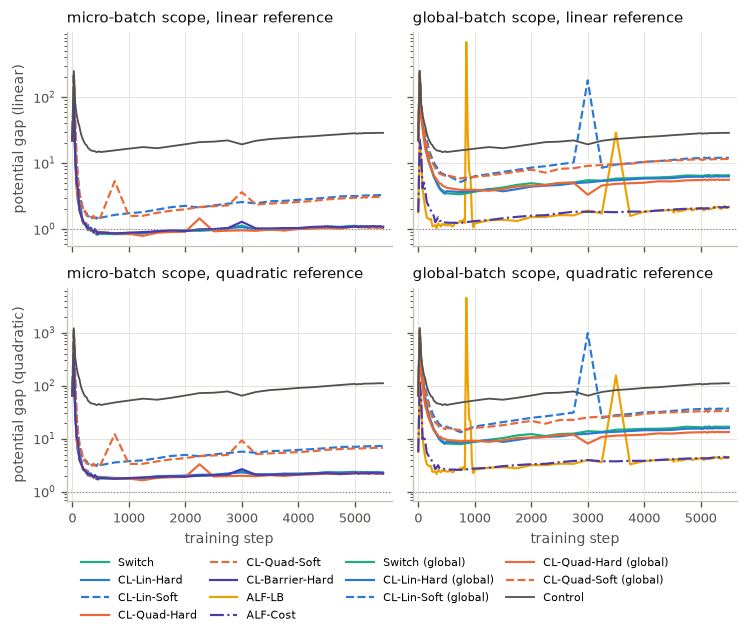

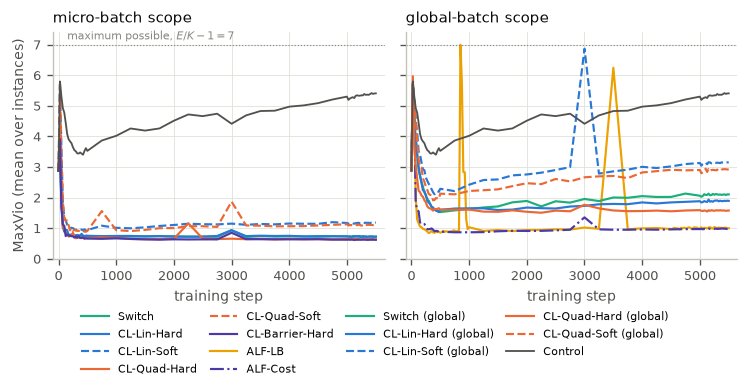

In [10]:
def trajectories(value, name, ylabel, log, costs=COSTS):
    """The two trajectory figures (normalized gap, MaxVio): mean over the primary population per step."""
    nrows = len(costs)
    fig, axes = plt.subplots(
        nrows, 2, figsize=(6.3, 2.05 * nrows + 1.2), sharex=True, sharey="row", squeeze=False
    )
    primary_rows = REF[~REF.stress]
    handles = {}
    for i, cost in enumerate(costs):
        rows = primary_rows[primary_rows.cost_family == cost]
        for j, (scope, title) in enumerate(
            (("micro", "micro-batch scope"), ("global", "global-batch scope"))
        ):
            ax = axes[i][j]
            for arm in ARMS_PRESENT:
                m = meta(arm)
                if m["scope"] not in (scope, "none"):
                    continue
                series = rows[rows.arm == arm].groupby("step")[value].mean()
                (h,) = ax.plot(
                    series.index,
                    series.values,
                    m["dash"],
                    color=m["color"],
                    label=m["label"],
                    lw=1.1 if arm == "control" else 1.3,
                )
                handles.setdefault(m["label"], h)
            if log:
                ax.set_yscale("log")
            if value == "gap_normalized":
                ax.axhline(1.0, color=MUTED, lw=0.7, ls=":")
                ax.set_title(f"{title}, {cost} reference", loc="left", color=INK)
            else:
                ax.axhline(7.0, color=MUTED, lw=0.7, ls=":")
                ax.set_ylim(0, 7.4)
                ax.set_title(title, loc="left", color=INK)
                if j == 0:
                    ax.text(
                        150,
                        7.05,
                        "maximum possible, $E/K - 1 = 7$",
                        fontsize=6.5,
                        color=MUTED,
                        va="bottom",
                    )
            if i == nrows - 1:
                ax.set_xlabel("training step")
            if j == 0:
                ax.set_ylabel(f"potential gap ({cost})" if value == "gap_normalized" else ylabel)
            ax.set_xlim(-100, 5650)
    order = [meta(a)["label"] for a in ARMS_PRESENT if meta(a)["label"] in handles]
    fig.legend(
        [handles[k] for k in order],
        order,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, 0.0),
        handlelength=2.4,
        columnspacing=1.1,
        fontsize=6.9,
    )
    fig.tight_layout(rect=(0, 0.17 if nrows == 1 else 0.11, 1, 1))
    save_figure(fig, name)
    plt.show()


trajectories("gap_normalized", "fig_ex_phi_gap_trajectories", "", log=True)
trajectories(
    "maxvio",
    "fig_ex_maxvio_trajectories",
    "MaxVio (mean over instances)",
    log=False,
    costs=("linear",),
)

In [11]:
# The numbers the text quotes about the trajectories over training. MaxVio is the same in both reference
# rows, so the linear rows are used.
mv = REF[~REF.stress & (REF.cost_family == "linear")].groupby(["arm", "step"]).maxvio.mean()
dead = REF[~REF.stress & (REF.cost_family == "linear")].groupby(["arm", "step"]).dead_experts.mean()
step0 = mv.xs(0, level="step")
note(
    "over training",
    "mean MaxVio at step 0, range over arms",
    f"{step0.min():.3f} to {step0.max():.3f}",
)
# Probe dumps in which a balancing arm is almost collapsed: the four single-dump episodes.
episodes = {("alflb", 850), ("alflb", 875), ("alflb", 3500), ("rosenthal_linear_soft_global", 3000)}
for arm, step in sorted(episodes):
    note(
        "over training",
        f"episode {arm} step {step}",
        f"MaxVio {mv[(arm, step)]:.2f}, dead {dead[(arm, step)]:.1f}",
    )
note("over training", "ALF-LB MaxVio at step 975", f"{mv[('alflb', 975)]:.2f}")
after = mv[
    (mv.index.get_level_values("step") > 500) & (mv.index.get_level_values("arm") != "control")
]
rest = after[[i not in episodes for i in after.index]]
note(
    "over training",
    "largest balancing-arm MaxVio after step 500 without the episodes",
    f"{rest.max():.3f}, {rest.idxmax()[0]} at step {rest.idxmax()[1]}",
)
control = mv.loc["control"]
late_low = control[control.index > 25]
note(
    "over training",
    "control MaxVio",
    f"peak {control.max():.2f} at step {control.idxmax()}, lowest after it {late_low.min():.2f} at step {late_low.idxmin()}, {control[FINAL_STEP]:.2f} at step {FINAL_STEP}",
)
for k, v in NUMBERS["over training"].items():
    print(f"{k}: {v}")

mean MaxVio at step 0, range over arms: 2.882 to 2.884
episode alflb step 850: MaxVio 6.99, dead 48.8
episode alflb step 875: MaxVio 5.74, dead 8.8
episode alflb step 3500: MaxVio 6.25, dead 21.3
episode rosenthal_linear_soft_global step 3000: MaxVio 6.87, dead 40.0
ALF-LB MaxVio at step 975: 0.97
largest balancing-arm MaxVio after step 500 without the episodes: 3.159, rosenthal_linear_soft_global at step 5150
control MaxVio: peak 5.80 at step 25, lowest after it 3.41 at step 425, 5.41 at step 5500


### Numerator and denominator over training (`fig_ex_gap_parts_trajectories`)

The normalized gap compares arms at the same probe step on the same tokens, and there the denominator, the gap of the round-robin profile, is nearly common to the softmax arms (section 2). Over training, the denominator moves as well, so a rising normalized gap need not mean that the routing got worse. This part splits the drift into its two parts:

- **raw gap:** the per-assignment gap $\Delta\phi$ = `gap_per_token / K`, in units of the affinities;
- **round-robin gap:** the denominator, `normalizer`, the same for every token count once divided by $nK$;
- **MaxVio**, for comparison, which does not depend on the reference.

**The statistic.** For each arm, reference and quantity: the mean over the 40 instances of the primary population over the late window (21 steps), divided by the mean over the same 40 instances at step 1000. Step 1000 is a shared probe step, after every balancing arm has balanced. A ratio below 1 means that the quantity fell.

The figure draws the raw gap and the round-robin gap over training under the linear reference, faceted by scope like the trajectory figures above, with the control in both columns. The raw gaps of the two sigmoid bias arms are not on the scale of the softmax arms (rule 5), so the figure shows each arm's course, not a comparison between the two groups.

late window / step 1000, mean over the 40 primary instances (MaxVio is the same under both references):
                                normalized gap           raw gap           round-robin gap            MaxVio          
                                        linear quadratic  linear quadratic          linear quadratic  linear quadratic
arm                                                                                                                   
switch                                  1.2972    1.3093  0.9187    0.9278          0.7029    0.7029  0.9784    0.9784
rosenthal_linear_hard                   1.2771    1.2933  0.9056    0.9177          0.7044    0.7044  0.9838    0.9838
rosenthal_linear_soft                   1.8635    1.9155  1.3482    1.3849          0.7262    0.7261  1.1555    1.1555
rosenthal_quadratic_hard                1.2486    1.2560  0.8965    0.9022          0.7114    0.7114  0.9322    0.9322
rosenthal_quadratic_soft                1.9197    1.9848  1.389

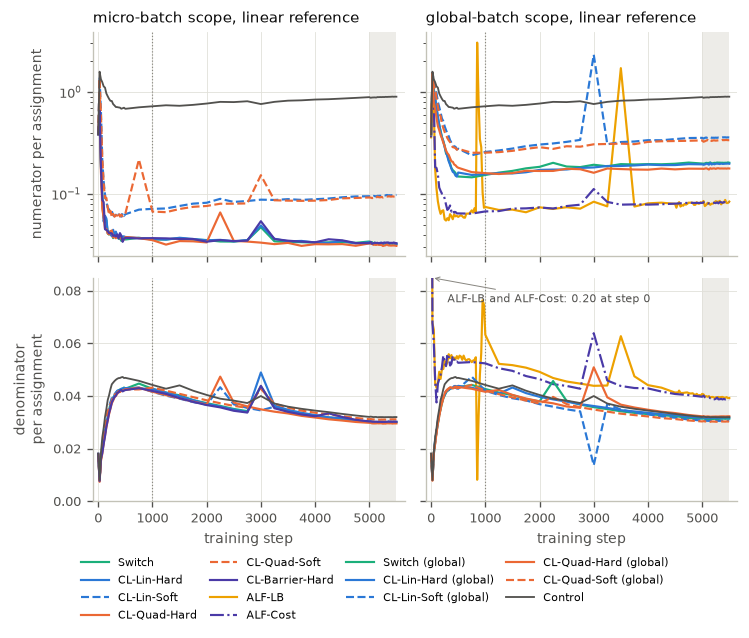

normalized gap, late / step 1000, hard micro arms (lin; quad): 1.2372 to 1.2972; 1.2301 to 1.3093
normalized gap, late / step 1000, bias arms (lin; quad): 1.5953 to 1.7043; 1.5954 to 1.6476
normalized gap, late / step 1000, other balancing arms (soft micro, global loss) (lin; quad): 1.4195 to 1.9197; 1.4587 to 2.1445
normalized gap, late / step 1000, bias and other balancing arms (all but the hard micro arms) (lin; quad): 1.4195 to 1.9197; 1.4587 to 2.1445
normalized gap, late / step 1000, all 13 balancing arms (lin; quad): 1.2372 to 1.9197; 1.2301 to 2.1445
normalized gap, late / step 1000, control (lin; quad): 1.7210 to 1.7210; 2.0842 to 2.0842
raw gap, late / step 1000, hard micro arms (lin; quad): 0.8965 to 0.9187; 0.8924 to 0.9278
raw gap, late / step 1000, bias arms (lin; quad): 1.1000 to 1.2165; 1.0655 to 1.2197
raw gap, late / step 1000, other balancing arms (soft micro, global loss) (lin; quad): 1.1086 to 1.3899; 1.1363 to 1.5761
raw gap, late / step 1000, bias and other balan

In [12]:
# The drift of the normalized gap, split into its numerator (raw gap) and denominator (round-robin gap).
DRIFT_STEP = 1000  # a shared probe step after every balancing arm has balanced
PROBE_TOKENS = (
    16_384  # tokens of a probe unit: gap_normalized = gap_per_token * PROBE_TOKENS / normalizer
)
assert DRIFT_STEP in SHARED_STEPS
prim = REF[~REF.stress].copy()
assert np.allclose(
    prim.gap_per_token * PROBE_TOKENS / prim.normalizer, prim.gap_normalized, rtol=1e-9, atol=1e-12
)
prim["rr"] = prim.normalizer / (
    PROBE_TOKENS * K
)  # round-robin gap per assignment, on the scale of dphi
assert prim[prim.step == DRIFT_STEP].groupby(["arm", "cost_family"]).size().eq(40).all()

DRIFT_QUANTITIES = {
    "gap_normalized": "normalized gap",
    "dphi": "raw gap",
    "rr": "round-robin gap",
    "maxvio": "MaxVio",
}


def drift_ratio(value, cost):
    """Per arm: mean over the 40 primary instances and the 21 late-window steps / mean over the 40 at step 1000."""
    rows = prim[prim.cost_family == cost]
    late = rows[rows.step.isin(LATE_STEPS)].groupby("arm")[value].mean()
    start = rows[rows.step == DRIFT_STEP].groupby("arm")[value].mean()
    return late / start


DRIFT = pd.DataFrame({(q, c): drift_ratio(q, c) for q in DRIFT_QUANTITIES for c in COSTS}).loc[
    ARMS_PRESENT
]
print(
    f"late window / step {DRIFT_STEP}, mean over the 40 primary instances (MaxVio is the same under both references):"
)
print(DRIFT.rename(columns=DRIFT_QUANTITIES, level=0).round(4).to_string())

S = "over training, drift"
DRIFT_GROUPS = {
    "hard micro arms": LEAD_HARD,
    "bias arms": sorted(BIAS_ARMS),
    "other balancing arms (soft micro, global loss)": SOFT_MICRO + HARD_GLOBAL + SOFT_GLOBAL,
    "bias and other balancing arms (all but the hard micro arms)": [
        a for a in ARMS_PRESENT if a not in LEAD_HARD + ["control"]
    ],
    "all 13 balancing arms": [a for a in ARMS_PRESENT if a != "control"],
    "control": ["control"],
}


def span(values):
    return f"{values.min():.4f} to {values.max():.4f}"


for q in ("gap_normalized", "dphi", "rr"):
    for group, arms in DRIFT_GROUPS.items():
        note(
            S,
            f"{DRIFT_QUANTITIES[q]}, late / step {DRIFT_STEP}, {group} (lin; quad)",
            f"{span(DRIFT.loc[arms, (q, 'linear')])}; {span(DRIFT.loc[arms, (q, 'quadratic')])}",
        )
for group, arms in DRIFT_GROUPS.items():
    note(
        S, f"MaxVio, late / step {DRIFT_STEP}, {group}", span(DRIFT.loc[arms, ("maxvio", "linear")])
    )
rr_all = DRIFT.loc[:, [("rr", c) for c in COSTS]]
note(
    S,
    f"round-robin gap falls from step {DRIFT_STEP} to the late window in every arm, both references",
    bool((rr_all < 1).all().all()),
)
note(
    S,
    f"round-robin gap, late / step {DRIFT_STEP}, all 14 arms, both references",
    span(pd.Series(rr_all.to_numpy().ravel())),
)

# Is the drift monotone? Rank correlation of the probe step with the mean normalized gap, over the probe steps >= 1000.
mean_gap = (
    prim[prim.step >= DRIFT_STEP].groupby(["arm", "cost_family", "step"]).gap_normalized.mean()
)
mono = {
    (a, c): spearman(
        pd.Series(mean_gap.loc[(a, c)].index, index=mean_gap.loc[(a, c)].index),
        mean_gap.loc[(a, c)],
    )
    for a in ARMS_PRESENT
    for c in COSTS
}
mono = pd.Series(mono).unstack()
for group in ("hard micro arms", "bias arms", "other balancing arms (soft micro, global loss)"):
    arms = DRIFT_GROUPS[group]
    note(
        S,
        f"Spearman of the probe step with the normalized gap, steps >= {DRIFT_STEP}, {group} (lin; quad)",
        f"{span(mono.loc[arms, 'linear'])}; {span(mono.loc[arms, 'quadratic'])}",
    )

# Early balance: MaxVio at step 500 against the late window, for the hard micro arms and the bias arms.
mv_step = prim[prim.cost_family == "linear"].groupby(["arm", "step"]).maxvio.mean()
fast = LEAD_HARD + sorted(BIAS_ARMS)
note(
    S, "MaxVio at step 500, hard micro and bias arms", span(mv_step.xs(500, level="step").loc[fast])
)
note(
    S,
    "MaxVio over the late window, hard micro and bias arms",
    span(
        prim[(prim.cost_family == "linear") & prim.step.isin(LATE_STEPS)]
        .groupby("arm")
        .maxvio.mean()
        .loc[fast]
    ),
)

# The round-robin gap per assignment over the late window, softmax against sigmoid arms (the yardstick's units).
rr_late = prim[prim.step.isin(LATE_STEPS)].groupby(["arm", "cost_family"]).rr.mean().unstack()
softmax_arms = [a for a in ARMS_PRESENT if a not in BIAS_ARMS]
for cost in COSTS:
    note(
        S,
        f"round-robin gap per assignment, late window ({cost}): softmax arms; sigmoid arms",
        f"{span(rr_late.loc[softmax_arms, cost])}; {span(rr_late.loc[sorted(BIAS_ARMS), cost])}",
    )


RR_TOP = 0.085  # top of the round-robin panels; only the sigmoid arms' step-0 values lie above it, and the panel says so


def gap_parts_figure(cost="linear"):
    """Raw gap (top) and round-robin gap (bottom) per assignment over training, faceted by scope."""
    fig, axes = plt.subplots(2, 2, figsize=(6.3, 5.3), sharex=True, sharey="row", squeeze=False)
    rows = prim[prim.cost_family == cost]
    handles = {}
    panels = (
        ("dphi", "numerator per assignment", True),
        ("rr", "denominator\nper assignment", False),
    )
    for i, (value, ylabel, log) in enumerate(panels):
        for j, (scope, title) in enumerate(
            (("micro", "micro-batch scope"), ("global", "global-batch scope"))
        ):
            ax = axes[i][j]
            ax.axvspan(LATE_STEPS[0], LATE_STEPS[-1], color=GRID_INK, alpha=0.6, lw=0)
            ax.axvline(DRIFT_STEP, color=MUTED, lw=0.7, ls=":")
            above = {}
            for arm in ARMS_PRESENT:
                m = meta(arm)
                if m["scope"] not in (scope, "none"):
                    continue
                series = rows[rows.arm == arm].groupby("step")[value].mean()
                (h,) = ax.plot(
                    series.index,
                    series.values,
                    m["dash"],
                    color=m["color"],
                    label=m["label"],
                    lw=1.1 if arm == "control" else 1.3,
                )
                handles.setdefault(m["label"], h)
                if not log:
                    for step, v in series[series > RR_TOP].items():
                        above.setdefault((step, round(v, 2)), []).append(m["label"])
            if log:
                ax.set_yscale("log")
            else:
                ax.set_ylim(0, RR_TOP)
                for k, ((step, v), labels) in enumerate(sorted(above.items())):
                    ax.annotate(
                        f"{' and '.join(labels)}: {v:.2f} at step {step}",
                        xy=(step, RR_TOP),
                        xytext=(300, RR_TOP * (0.93 - 0.08 * k)),
                        fontsize=6.5,
                        color=INK_2,
                        va="top",
                        arrowprops={"arrowstyle": "->", "color": MUTED, "lw": 0.6},
                    )
                    note(
                        S,
                        f"round-robin gap above the figure's panel ({scope})",
                        f"{', '.join(labels)}: {v:.2f} at step {step}",
                    )
            if i == 0:
                ax.set_title(f"{title}, {cost} reference", loc="left", color=INK)
            else:
                ax.set_xlabel("training step")
            if j == 0:
                ax.set_ylabel(ylabel)
            ax.set_xlim(-100, 5650)
    order = [meta(a)["label"] for a in ARMS_PRESENT if meta(a)["label"] in handles]
    fig.legend(
        [handles[k] for k in order],
        order,
        loc="lower center",
        ncol=4,
        bbox_to_anchor=(0.5, 0.0),
        handlelength=2.4,
        columnspacing=1.1,
        fontsize=6.9,
    )
    fig.tight_layout(rect=(0, 0.11, 1, 1))
    save_figure(fig, "fig_ex_gap_parts_trajectories")
    plt.show()


gap_parts_figure()
for k, v in NUMBERS[S].items():
    print(f"{k}: {v}")

---
## 4. What the spread is made of: per-layer curves, one panel per arm

The standard deviations in the ranking table are large because layers differ, not because the measurement is noisy. These panels show that directly:

- **Grey band:** the interquartile range over the 40 instances of the primary population.
- **Layer curves:** each arm's mean per layer, drawn on top of the band.

Layer is ordinal, so it is drawn as one hue from light to dark rather than as eight categorical colours, which would imply the layers are unrelated categories. Both reference costs are drawn, because rule 1 binds here too.

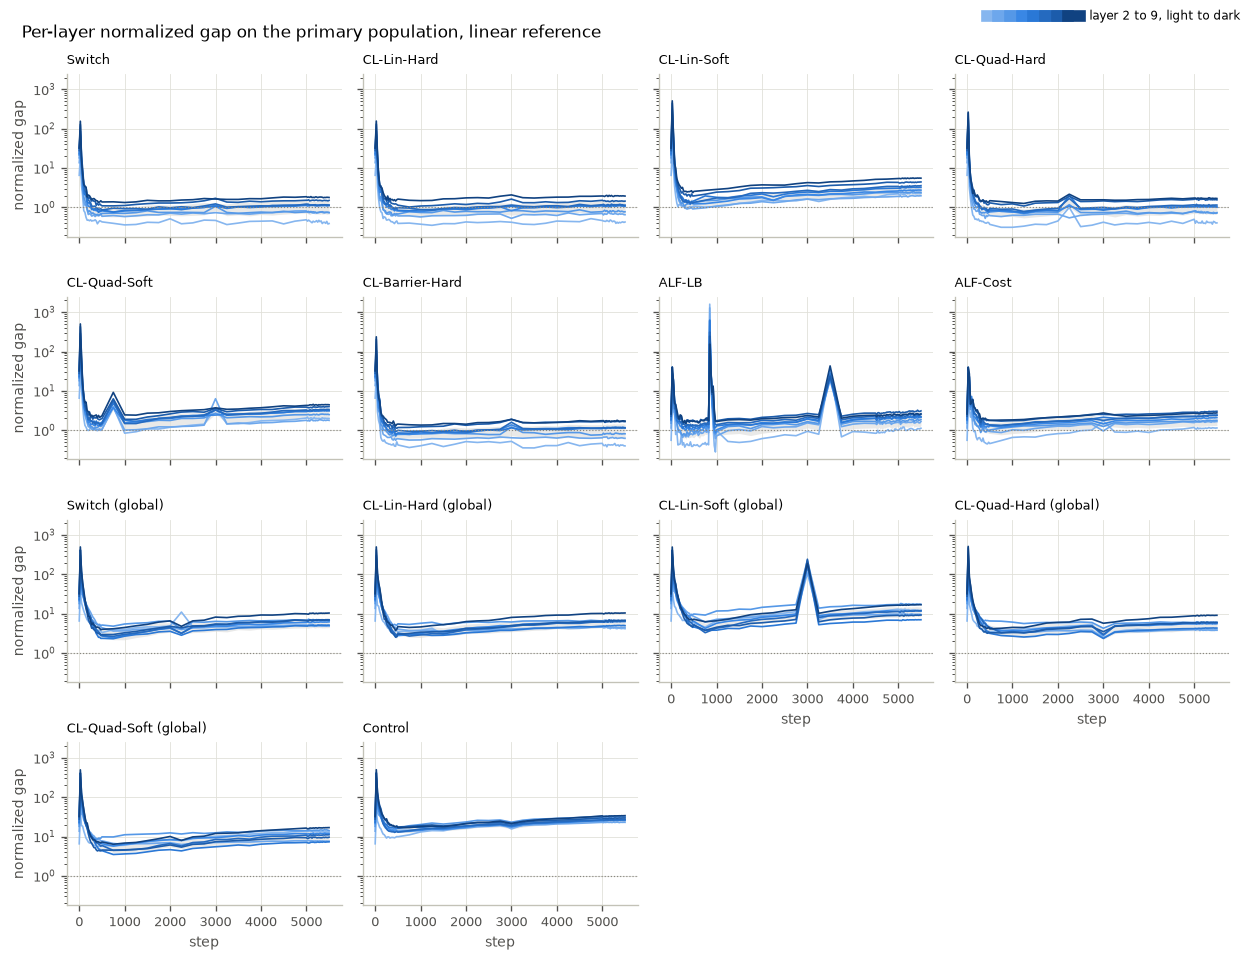

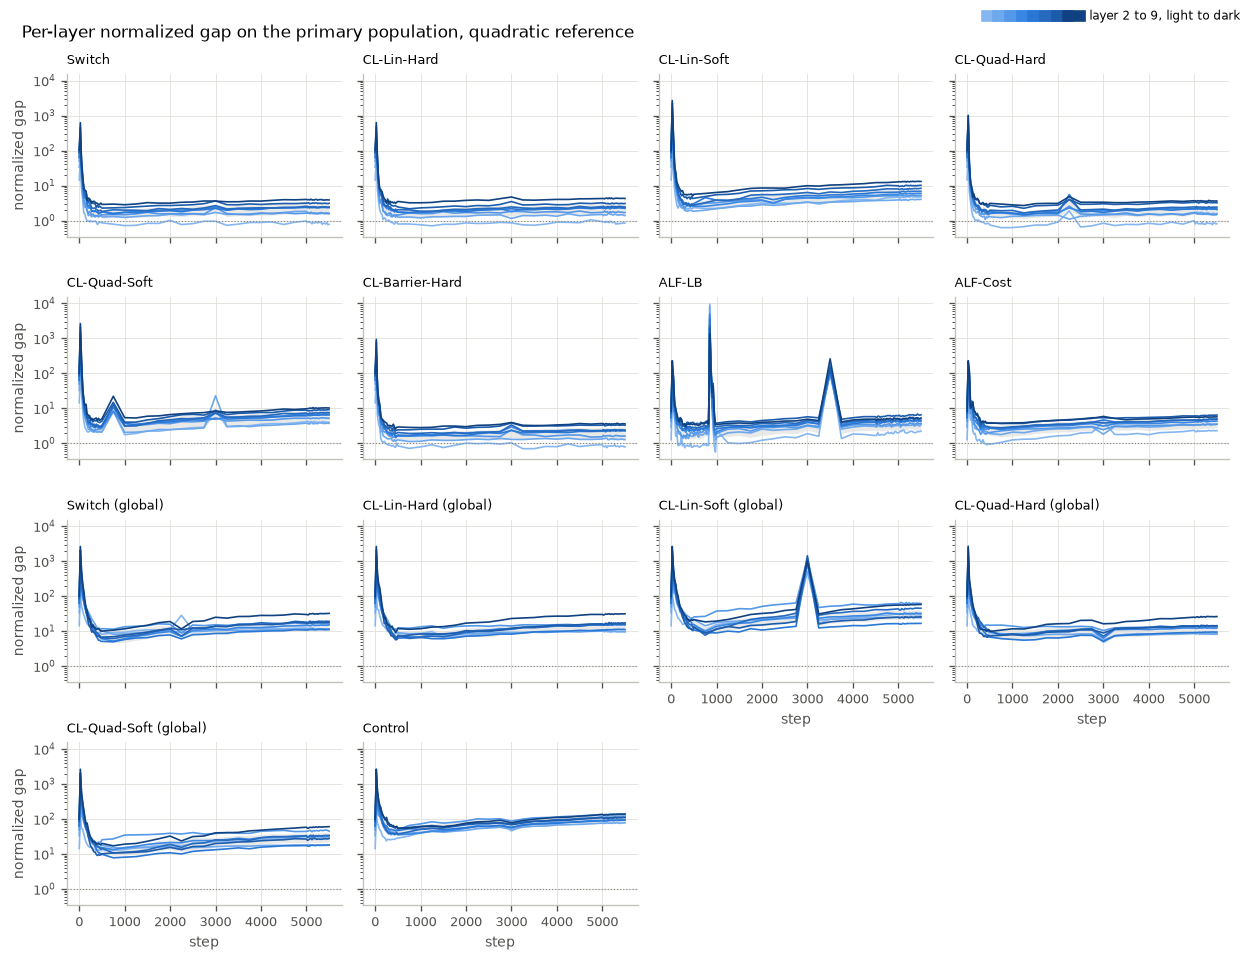

quadratic hard, late window, linear reference, mean per layer: {2: 0.42, 3: 0.75, 4: 0.74, 5: 1.04, 6: 1.06, 7: 1.14, 8: 1.59, 9: 1.7}


In [13]:
def layer_panels(cost, ncols=4):
    rows = REF[~REF.stress & (REF.cost_family == cost)]
    arms = [a for a in ARMS_PRESENT if a in set(rows.arm)]
    layers = sorted(rows.layer.unique())
    nrows = -(-len(arms) // ncols)
    fig, axes = plt.subplots(
        nrows, ncols, sharex=True, sharey=True, squeeze=False, figsize=(2.6 * ncols, 2.0 * nrows)
    )
    for i, arm in enumerate(arms):
        ax = axes[i // ncols][i % ncols]
        g = rows[rows.arm == arm]
        band = g.groupby("step").gap_normalized
        ax.fill_between(
            band.quantile(0.25).index,
            band.quantile(0.25).values,
            band.quantile(0.75).values,
            color=MUTED,
            alpha=0.18,
            linewidth=0,
        )
        for k, layer in enumerate(layers):
            curve = g[g.layer == layer].groupby("step").gap_normalized.mean()
            ax.plot(curve.index, curve.values, color=LAYER_RAMP[k % len(LAYER_RAMP)], linewidth=1.0)
        ax.set_yscale("log")
        ax.axhline(1.0, color=MUTED, linewidth=0.7, linestyle=":")
        ax.set_title(meta(arm)["label"], loc="left", fontsize=8)
        if i % ncols == 0:
            ax.set_ylabel("normalized gap")
        # A panel with no panel beneath it keeps its own tick labels, which sharex would otherwise hide.
        if i + ncols >= len(arms):
            ax.set_xlabel("step")
            ax.tick_params(labelbottom=True)
    for j in range(len(arms), nrows * ncols):
        axes[j // ncols][j % ncols].axis("off")
    # Layer is encoded by lightness alone, so it gets one gradient swatch rather than eight entries.
    swatch = tuple(plt.Line2D([], [], color=c, linewidth=7) for c in LAYER_RAMP[: len(layers)])
    fig.legend(
        handles=[swatch],
        labels=[f"layer {layers[0]} to {layers[-1]}, light to dark"],
        handler_map={tuple: HandlerTuple(ndivide=None, pad=0.0)},
        handlelength=len(layers),
        loc="upper right",
        fontsize=7,
    )
    fig.suptitle(
        f"Per-layer normalized gap on the primary population, {cost} reference", x=0.02, ha="left"
    )
    fig.tight_layout()
    plt.show()


for cost in COSTS:
    layer_panels(cost)

# The example the text quotes on aggregation: the layer means of the quadratic hard arm.
qh = (
    PRIMARY[(PRIMARY.arm == "rosenthal_quadratic_hard") & (PRIMARY.cost_family == "linear")]
    .groupby("layer")
    .gap.mean()
)
print("quadratic hard, late window, linear reference, mean per layer:", qh.round(2).to_dict())
note(
    "per-layer spread",
    "quadratic hard layer means (lin)",
    f"{qh.iloc[0]:.2f} in layer {qh.index[0]} to {qh.iloc[-1]:.2f} in layer {qh.index[-1]}",
)

---
## 5. Where the gap comes from: affinity shortfall and congestion excess (`tab_ex_phi_gap_decomposition`)

`gap_per_token` splits into two per-token parts that sum to it exactly:

    affinity_shortfall = (A* - A_realized) / n        how much affinity the MINIMIZER gave up
    congestion_excess  = (Cong_realized - Cong*) / n  how much congestion the ROUTER overpaid

**Only their sum is bounded below.** Either part may be negative.

- **Arms without an expert bias:** `affinity_shortfall` is negative by construction, not by defect. Such a router *is* the argmax of its own affinity, so its realized affinity is the maximum achievable, and the minimizer can only score below it.
- **The two bias arms:** a positive `affinity_shortfall` would mean the bias is acting on the selection. That is a read on the arm, not a warning, and only these two arms can produce it. Over the late window their mean is negative as well (decomposition table).

These are raw quantities, so rule 5 applies: they are not comparable between the sigmoid bias arms and the softmax arms. The table gives them per assignment, i.e. per token divided by K, times 100.

In [14]:
dec_columns = {}
for cost in COSTS:
    g = PRIMARY[PRIMARY.cost_family == cost].groupby("arm")
    mean, std = g[["dphi", "aff", "cong"]].mean(), g.dphi.std()
    dec_columns[f"{cost} gap"] = [
        sig3_pm(100 * mean.loc[a, "dphi"], 100 * std.loc[a]) for a in RANKING
    ]
    dec_columns[f"{cost} shortfall"] = [sig3(100 * mean.loc[a, "aff"]) for a in RANKING]
    dec_columns[f"{cost} excess"] = [sig3(100 * mean.loc[a, "cong"]) for a in RANKING]
dec_lead = [f"{meta(a)['table']} & {scope_tex[meta(a)['scope']]}" for a in RANKING]
dec_rows = render_rows("tab_ex_phi_gap_decomposition", dec_lead, dec_columns)
write_rows("tab_ex_phi_gap_decomposition", dec_rows)

split = (
    PRIMARY.groupby(["arm", "cost_family"])[["dphi", "aff", "cong"]].mean().unstack("cost_family")
)
print("\nper assignment x 100, late window, primary population:")
print((100 * split).loc[RANKING].round(3).to_string())
for cost in COSTS:
    share = -split[("aff", cost)] / split[("dphi", cost)]
    note(
        "decomposition",
        f"affinity shortfall as a share of the gap, {cost}",
        f"{100 * share.min():.2f} to {100 * share.max():.2f} %, negative for every arm: {bool((split[('aff', cost)] < 0).all())}",
    )

wrote tables/tab_ex_phi_gap_decomposition.tex, 14 lines

per assignment x 100, late window, primary population:
                                   dphi              aff              cong          
cost_family                      linear quadratic linear quadratic  linear quadratic
arm                                                                                 
rosenthal_quadratic_hard          3.160     6.594 -0.041    -0.042   3.201     6.636
switch                            3.280     6.935 -0.043    -0.044   3.324     6.979
rosenthal_linear_hard             3.287     7.015 -0.044    -0.044   3.331     7.059
rosenthal_barrier_hard            3.312     6.727 -0.043    -0.044   3.355     6.772
alflb                             8.206    16.924 -0.206    -0.212   8.412    17.136
rosenthal_price_barrier           8.205    16.976 -0.202    -0.208   8.407    17.184
rosenthal_quadratic_soft          9.345    20.388 -0.126    -0.128   9.472    20.516
rosenthal_linear_soft             9.63

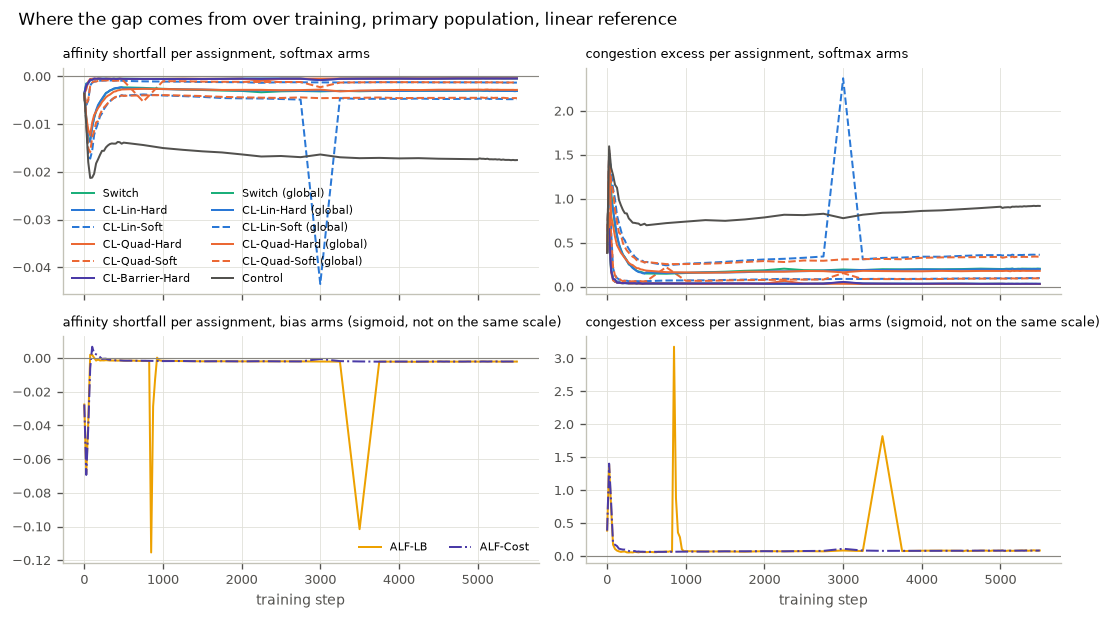

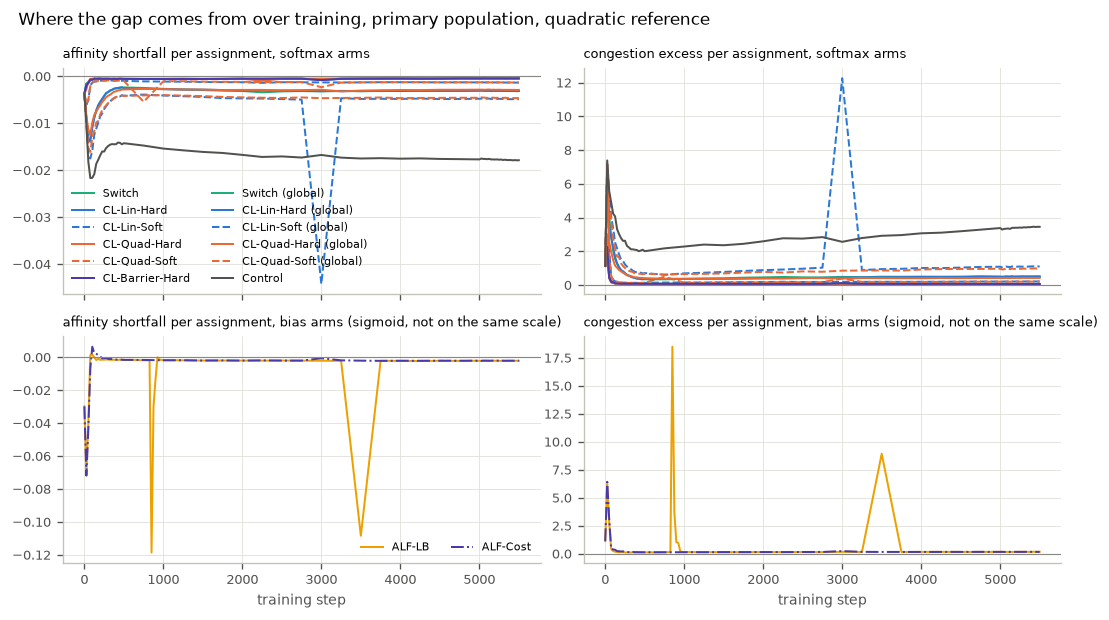

In [15]:
def decomposition(cost):
    groups = [
        ("softmax arms", [a for a in ARMS_PRESENT if a not in BIAS_ARMS]),
        ("bias arms (sigmoid, not on the same scale)", [a for a in ARMS_PRESENT if a in BIAS_ARMS]),
    ]
    fig, axes = plt.subplots(
        len(groups), 2, figsize=(9, 2.6 * len(groups)), sharex=True, squeeze=False
    )
    rows = REF[~REF.stress & (REF.cost_family == cost)]
    for r, (title, arms) in enumerate(groups):
        for c, value in enumerate(("aff", "cong")):
            ax = axes[r][c]
            for arm in arms:
                m = meta(arm)
                series = rows[rows.arm == arm].groupby("step")[value].mean()
                ax.plot(
                    series.index,
                    series.values,
                    m["dash"],
                    color=m["color"],
                    label=m["label"],
                    linewidth=1.2,
                )
            ax.axhline(0.0, color=MUTED, linewidth=0.7)
            name = "affinity shortfall" if value == "aff" else "congestion excess"
            ax.set_title(f"{name} per assignment, {title}", loc="left", fontsize=8)
            if r == len(groups) - 1:
                ax.set_xlabel("training step")
            if c == 0:
                ax.legend(loc="best", fontsize=6.5, ncol=2)
    fig.suptitle(
        f"Where the gap comes from over training, primary population, {cost} reference",
        x=0.02,
        ha="left",
    )
    fig.tight_layout()
    plt.show()


for cost in COSTS:
    decomposition(cost)

---
## 6. The stress unit, ranked on its own

The strided asset's first half is the pre-registered stress case. Its demand is concentrated and dominated by a single content cluster, and its optimum has to evict thousands of tokens from one expert, so its gap is several times that of a typical unit.

It is ranked on its own (rule 3, decision 0049 §5) and never blended into the primary mean. **An arm that wins one ranking and loses the other is a finding.** Concentrated demand of this kind also occurs in training, but its weight in a blended mean would be set by our draw of probe batches.

This section shows the stress unit over training, the per-layer numbers behind its ranking, and how much of that ranking rests on one game instance.

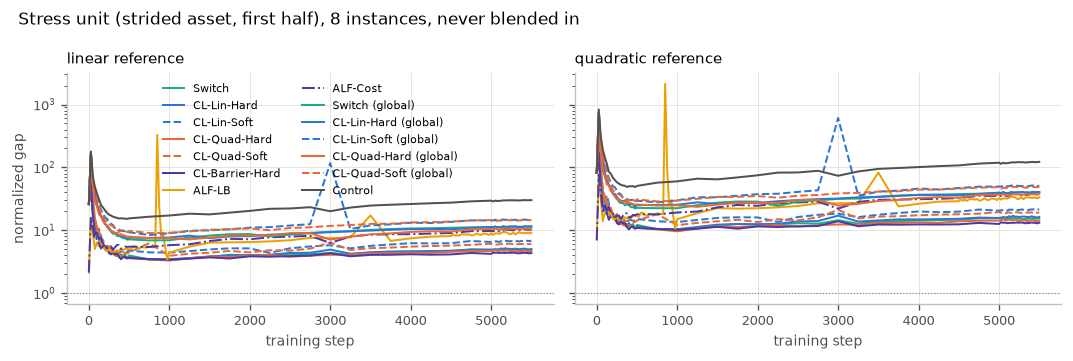

stress unit / primary population, late window:
cost_family                      linear  quadratic
arm                                               
rosenthal_quadratic_hard           4.48       6.55
switch                             4.53       6.72
rosenthal_linear_hard              4.66       7.06
rosenthal_barrier_hard             4.02       5.94
alflb                              4.35       7.65
rosenthal_price_barrier            4.80       8.45
rosenthal_quadratic_soft           2.01       2.91
rosenthal_linear_soft              2.09       2.96
rosenthal_quadratic_hard_global    1.89       2.80
rosenthal_linear_hard_global       1.81       2.57
switch_global                      1.76       2.38
rosenthal_quadratic_soft_global    1.26       1.47
rosenthal_linear_soft_global       1.22       1.39
control                            1.05       1.10

stress-unit order, linear: rosenthal_barrier_hard, rosenthal_quadratic_hard, switch, rosenthal_linear_hard, rosenthal_quadratic_soft, ro

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0), sharex=True, sharey=True)
stress_rows = REF[REF.stress]
for ax, cost in zip(axes, COSTS):
    rows = stress_rows[stress_rows.cost_family == cost]
    for arm in ARMS_PRESENT:
        m = meta(arm)
        series = rows[rows.arm == arm].groupby("step").gap_normalized.mean()
        ax.plot(
            series.index,
            series.values,
            m["dash"],
            color=m["color"],
            label=m["label"],
            linewidth=1.2,
        )
    ax.set_yscale("log")
    ax.axhline(1.0, color=MUTED, linewidth=0.7, linestyle=":")
    ax.set_title(f"{cost} reference", loc="left")
    ax.set_xlabel("training step")
axes[0].set_ylabel("normalized gap")
axes[0].legend(loc="best", fontsize=6.5, ncol=2)
fig.suptitle(
    "Stress unit (strided asset, first half), 8 instances, never blended in", x=0.02, ha="left"
)
fig.tight_layout()
plt.show()

# Stress / primary ratio per arm, and the ranking on the stress unit.
ratio = gap_s["mean"] / gap_p["mean"]
print("stress unit / primary population, late window:")
print(ratio.loc[RANKING].round(2).to_string())
order_s = {c: gap_s[("mean", c)].sort_values().index.tolist() for c in COSTS}
for cost in COSTS:
    print(f"\nstress-unit order, {cost}: {', '.join(order_s[cost])}")
lead_hard = [
    "rosenthal_barrier_hard",
    "rosenthal_quadratic_hard",
    "switch",
    "rosenthal_linear_hard",
]  # LEAD_HARD in stress order
hard_bias = lead_hard + sorted(BIAS_ARMS)
note(
    "stress unit",
    "stress / primary, hard micro and bias arms (lin)",
    f"{ratio.loc[hard_bias, 'linear'].min():.2f} to {ratio.loc[hard_bias, 'linear'].max():.2f}",
)
for group, arms in (
    ("soft micro", SOFT_MICRO),
    ("hard global", HARD_GLOBAL),
    ("soft global", SOFT_GLOBAL),
    ("control", ["control"]),
):
    note(
        "stress unit",
        f"stress / primary, {group} (lin)",
        f"{ratio.loc[arms, 'linear'].min():.2f} to {ratio.loc[arms, 'linear'].max():.2f}",
    )
# The share of a 48-instance mean the stress unit would carry, 8 of 48 instances weighted by its gaps.
for cost in COSTS:
    share = 8 * gap_s[("mean", cost)] / (8 * gap_s[("mean", cost)] + 40 * gap_p[("mean", cost)])
    note(
        "stress unit",
        f"stress unit's share of a 48-instance mean, leading arms ({cost})",
        f"{100 * share.loc[LEAD_HARD].min():.1f} to {100 * share.loc[LEAD_HARD].max():.1f} %",
    )
note(
    "stress unit",
    "stress / primary, leading arms (lin)",
    f"{ratio.loc[LEAD_HARD, 'linear'].min():.2f} to {ratio.loc[LEAD_HARD, 'linear'].max():.2f}",
)
for cost in COSTS:
    note(
        "stress unit",
        f"order of the leading arms, {cost}",
        ", ".join(f"{a} {gap_s.loc[a, ('mean', cost)]:.2f}" for a in order_s[cost][:4]),
    )
soft_micro = SOFT_MICRO
note(
    "stress unit",
    "both bias arms behind both soft micro arms, under both references",
    all(
        gap_s.loc[b, ("mean", c)] > gap_s.loc[s, ("mean", c)]
        for b in BIAS_ARMS
        for s in soft_micro
        for c in COSTS
    ),
)

In [17]:
# How much of the stress ranking rests on one instance: per layer, the four leading arms.
for cost in COSTS:
    per_layer = STRESS[STRESS.arm.isin(lead_hard) & (STRESS.cost_family == cost)].pivot_table(
        index="layer", columns="arm", values="gap"
    )[lead_hard]
    print(f"stress unit, late window, {cost} reference, normalized gap per layer:")
    print(per_layer.round(2).to_string(), "\n")
load3 = STRESS[(STRESS.layer == 3) & (STRESS.cost_family == "linear")].set_index("arm").load
print(
    "stress unit, layer 3, late-window mean of max_e n_e / L:",
    load3.loc[lead_hard].round(2).to_dict(),
)


def paired_instances(frame, a, b, cost):
    """Instances in which arm a has the lower late-window mean, and the two population means."""
    x = frame[frame.cost_family == cost]
    m = x[x.arm == a].merge(x[x.arm == b], on=INSTANCE, suffixes=("_a", "_b"))
    return int((m.gap_a < m.gap_b).sum()), len(m), m.gap_a.mean(), m.gap_b.mean()


def paired_steps(rows, a, b, cost, value="gap_normalized"):
    """Late-window steps at which the mean over the population is lower for arm a."""
    x = rows[rows.cost_family == cost]
    sa = x[x.arm == a].groupby("step")[value].mean()
    sb = x[x.arm == b].groupby("step")[value].mean()
    return int((sa < sb).sum())


late_stress = LATE[LATE.stress]
steeper = [
    ("rosenthal_quadratic_hard", "rosenthal_linear_hard"),
    ("rosenthal_quadratic_soft", "rosenthal_linear_soft"),
    ("rosenthal_quadratic_hard_global", "rosenthal_linear_hard_global"),
    ("rosenthal_quadratic_soft_global", "rosenthal_linear_soft_global"),
]
print("\nsteeper cost on the stress unit (quadratic vs linear):")
lower = {c: [] for c in COSTS}
stress_steps = []
for a, b in steeper + [
    ("rosenthal_barrier_hard", "rosenthal_quadratic_hard"),
    ("rosenthal_barrier_hard", "rosenthal_linear_hard"),
]:
    pieces = []
    for cost in COSTS:
        wins, n, ma, mb = paired_instances(STRESS, a, b, cost)
        steps = paired_steps(late_stress, a, b, cost)
        pieces.append(
            f"{cost} {ma:.2f}/{mb:.2f} ({100 * (ma / mb - 1):+.1f} %), lower in {wins}/{n} instances, {steps}/{len(LATE_STEPS)} steps"
        )
        if (a, b) in steeper:
            lower[cost].append(100 * (1 - ma / mb))
            stress_steps.append(steps)
    print(f"  {a} vs {b}: " + "; ".join(pieces))
for cost in COSTS:
    note(
        "stress unit, concentrated demand",
        f"steeper cost lowers the stress gap by ({cost})",
        f"{min(lower[cost]):.2f} to {max(lower[cost]):.2f} %",
    )
note(
    "stress unit, concentrated demand",
    "steeper cost, late steps with the lower stress mean (4 pairs x 2 references)",
    ", ".join(map(str, stress_steps)) + f" of {len(LATE_STEPS)}",
)
for cost in COSTS:
    lh, br = (
        gap_s.loc["rosenthal_linear_hard", ("mean", cost)],
        gap_s.loc["rosenthal_barrier_hard", ("mean", cost)],
    )
    note(
        "stress unit, concentrated demand",
        f"linear hard above the softplus barrier ({cost})",
        f"{100 * (lh / br - 1):.1f} %",
    )
note(
    "stress unit, concentrated demand",
    "quadratic hard below linear hard, instances",
    "/".join(
        str(paired_instances(STRESS, "rosenthal_quadratic_hard", "rosenthal_linear_hard", c)[0])
        for c in COSTS
    )
    + " of 8",
)
note(
    "stress unit, concentrated demand",
    "softplus barrier below quadratic hard, instances",
    "/".join(
        str(paired_instances(STRESS, "rosenthal_barrier_hard", "rosenthal_quadratic_hard", c)[0])
        for c in COSTS
    )
    + " of 8",
)
note(
    "stress unit, concentrated demand",
    "layer 3, max load / L, barrier vs quadratic hard",
    f"{load3['rosenthal_barrier_hard']:.4f} vs {load3['rosenthal_quadratic_hard']:.4f}",
)

# The blended mean the rules forbid, and how one instance decides it.
blend = INST.groupby(["arm", "cost_family"]).gap.mean().unstack()
without3 = (
    INST[~(INST.stress & (INST.layer == 3))].groupby(["arm", "cost_family"]).gap.mean().unstack()
)
for cost in COSTS:
    order = blend[cost].sort_values().index.tolist()
    order3 = without3[cost].sort_values().index.tolist()
    print(
        f"\nall 48 instances, {cost}: {', '.join(f'{a} {blend.loc[a, cost]:.3f}' for a in order[:4])}"
    )
    print(
        f"without the stress unit's layer 3, {cost}: {', '.join(f'{a} {without3.loc[a, cost]:.3f}' for a in order3[:4])}"
    )
    note(
        "stress unit",
        f"48 instances, first arm and how much lower than the second ({cost})",
        f"{order[0]}, {100 * (1 - blend.loc[order[0], cost] / blend.loc[order[1], cost]):.2f} % below {order[1]}",
    )
    note(
        "stress unit, concentrated demand", f"first over the other 47 instances ({cost})", order3[0]
    )

stress unit, late window, linear reference, normalized gap per layer:
arm    rosenthal_barrier_hard  rosenthal_quadratic_hard  switch  rosenthal_linear_hard
layer                                                                                 
2                        1.37                      1.25    1.22                   1.29
3                        3.12                      6.35    6.28                   4.78
4                        4.40                      4.25    4.49                   4.78
5                        7.19                      6.31    5.66                   6.31
6                        3.26                      3.45    4.75                   4.72
7                        5.03                      4.11    3.88                   4.47
8                        6.01                      6.67    7.00                   7.63
9                        4.65                      5.46    6.07                   6.46 

stress unit, late window, quadratic reference, normalized 

  rosenthal_barrier_hard vs rosenthal_quadratic_hard: linear 4.38/4.73 (-7.4 %), lower in 4/8 instances, 21/21 steps; quadratic 13.16/14.42 (-8.7 %), lower in 3/8 instances, 21/21 steps
  rosenthal_barrier_hard vs rosenthal_linear_hard: linear 4.38/5.05 (-13.4 %), lower in 5/8 instances, 21/21 steps; quadratic 13.16/16.36 (-19.5 %), lower in 5/8 instances, 21/21 steps



all 48 instances, linear: rosenthal_barrier_hard 1.638, rosenthal_quadratic_hard 1.668, switch 1.724, rosenthal_linear_hard 1.747
without the stress unit's layer 3, linear: rosenthal_quadratic_hard 1.569, rosenthal_barrier_hard 1.607, switch 1.627, rosenthal_linear_hard 1.683

all 48 instances, quadratic: rosenthal_barrier_hard 4.040, rosenthal_quadratic_hard 4.239, switch 4.478, rosenthal_linear_hard 4.657
without the stress unit's layer 3, quadratic: rosenthal_quadratic_hard 3.841, rosenthal_barrier_hard 3.952, switch 4.089, rosenthal_linear_hard 4.406


---
## 7. Robustness of the ranking (`tab_ex_robustness`)

The ranking is a late-window mean over the primary population. The robustness table checks it on other cuts, in this column order:

- **Step 5500 alone:** the last probe dump, on the 40 instances of the primary population.
- **Each asset on its own,** over the late window. The assets split the 48 instances, and the strided asset is split once more into its two units:
  - **tail asset:** 16 instances. It is also the asset of the λ sweep;
  - **strided asset:** its second unit only, 8 instances;
  - **stress unit:** the strided asset's first unit, 8 instances. These are the stress columns of the ranking table again, shown here so the split is complete;
  - **spread asset:** 16 instances.

  The tail, strided and spread columns together are the primary population: its mean is their instance-weighted mean (16, 8 and 16 of 40).
- **All 48 instances:** the primary population and the stress unit blended over the late window. This is the mean the rules forbid as a headline. The thesis shows it only here, to make visible how much the stress unit moves it.

`ROBUSTNESS_CUTS` sets the columns; dropping an entry drops the column from the rows file.

After the table come two further checks:

- **The concentration screen as a sensitivity check (rule 2):** the mean over every instance against the mean over screened instances only.
- **The own-against-shared-instances check:** it confirms that every arm is averaged over the same instances.

In [18]:
def cut_mean(mask):
    """Mean over the instances in `mask` of their late-window means, per arm and reference."""
    return INST[mask].groupby(["arm", "cost_family"]).gap.mean().unstack()


# The cuts of the robustness table, in its column order. Step 5500 is the primary population at the last
# probe step; every other cut is a late-window mean. The three assets split the 48 instances, with the
# strided asset split once more into its second unit and the stress unit: tail 16, strided 8, stress 8,
# spread 16. So the primary mean is the instance-weighted mean of the tail, strided and spread columns.
step5500 = (
    REF[~REF.stress & (REF.step == FINAL_STEP)]
    .groupby(["arm", "cost_family"])
    .gap_normalized.mean()
    .unstack()
)
masks = {
    "tail asset": INST.asset == TAIL_ASSET,
    "strided asset": (INST.asset == STRESS_ASSET) & ~INST.stress,
    "stress unit": INST.stress,
    "spread asset": INST.asset == SPREAD_ASSET,
}
sizes = {
    name: INST[mask].groupby(["arm", "cost_family"]).size().unique().tolist()
    for name, mask in masks.items()
}
assert sizes == {
    "tail asset": [16],
    "strided asset": [8],
    "stress unit": [8],
    "spread asset": [16],
}, sizes
ROBUSTNESS_CUTS = {
    "step 5500": step5500,
    **{name: cut_mean(mask) for name, mask in masks.items()},
    "all 48": blend,
}
rob_columns = {
    f"{name} {cost}": [plain3(frame.loc[a, cost]) for a in RANKING]
    for name, frame in ROBUSTNESS_CUTS.items()
    for cost in COSTS
}
rob_rows = render_rows("tab_ex_robustness", [flat_label(a) for a in RANKING], rob_columns)
write_rows("tab_ex_robustness", rob_rows)
print(
    pd.concat({name: frame.loc[RANKING] for name, frame in ROBUSTNESS_CUTS.items()}, axis=1)
    .round(3)
    .to_string()
)
for cost in COSTS:
    note(
        "robustness",
        f"first arm of each cut ({cost})",
        ", ".join(f"{name}: {frame[cost].idxmin()}" for name, frame in ROBUSTNESS_CUTS.items()),
    )

deviation = step5500 / gap_p["mean"] - 1
print("\nstep 5500 against the late window, relative deviation:")
print((100 * deviation).loc[RANKING].round(2).to_string())
for cost in COSTS:
    same_order = (
        step5500[cost].sort_values().index.tolist()
        == gap_p[("mean", cost)].sort_values().index.tolist()
    )
    note(
        "robustness",
        f"step 5500 vs late window ({cost})",
        f"max |deviation| {100 * deviation[cost].abs().max():.2f} % ({deviation[cost].abs().idxmax()}), same order: {same_order}",
    )
mv_late = PRIMARY[PRIMARY.cost_family == "linear"].groupby("arm").maxvio.mean()
note("robustness", "lowest MaxVio of all arms", f"{mv_late.idxmin()} {mv_late.min():.3f}")
note(
    "robustness",
    "softplus barrier MaxVio below quadratic hard, late steps",
    f"{paired_steps(LATE[~LATE.stress], 'rosenthal_barrier_hard', 'rosenthal_quadratic_hard', 'linear', 'maxvio')}/{len(LATE_STEPS)}",
)
note(
    "robustness",
    "control is last in every column, both references",
    all(
        t.idxmax() == "control"
        for c in COSTS
        for t in [frame[c] for frame in ROBUSTNESS_CUTS.values()]
        + [gap_s[("mean", c)], gap_p[("mean", c)]]
    ),
)
note(
    "robustness",
    "control / ALF-LB and control / quadratic hard, primary (lin)",
    f"{gap_p.loc['control', ('mean', 'linear')] / gap_p.loc['alflb', ('mean', 'linear')]:.2f}, "
    f"{gap_p.loc['control', ('mean', 'linear')] / gap_p.loc['rosenthal_quadratic_hard', ('mean', 'linear')]:.2f}",
)
all48_5500 = (
    REF[REF.step == FINAL_STEP].groupby(["arm", "cost_family"]).gap_normalized.mean().unstack()
)
for cost in COSTS:
    first48 = all48_5500[cost].sort_values()
    note(
        "robustness",
        f"all 48 instances at step 5500 alone: first arm, how much lower than the second ({cost})",
        f"{first48.index[0]}, {100 * (1 - first48.iloc[0] / first48.iloc[1]):.2f} % below {first48.index[1]}",
    )

wrote tables/tab_ex_robustness.tex, 14 lines
                                step 5500           tail asset           strided asset           stress unit           spread asset            all 48          
cost_family                        linear quadratic     linear quadratic        linear quadratic      linear quadratic       linear quadratic  linear quadratic
arm                                                                                                                                                            
rosenthal_quadratic_hard            1.037     2.163      1.453     3.004         0.896     1.831       4.731    14.423        0.739     1.587   1.668     4.239
switch                              1.070     2.262      1.509     3.149         0.935     1.941       4.919    15.405        0.737     1.613   1.724     4.478
rosenthal_linear_hard               1.070     2.285      1.505     3.171         0.878     1.810       5.054    16.360        0.771     1.714   1.747     4

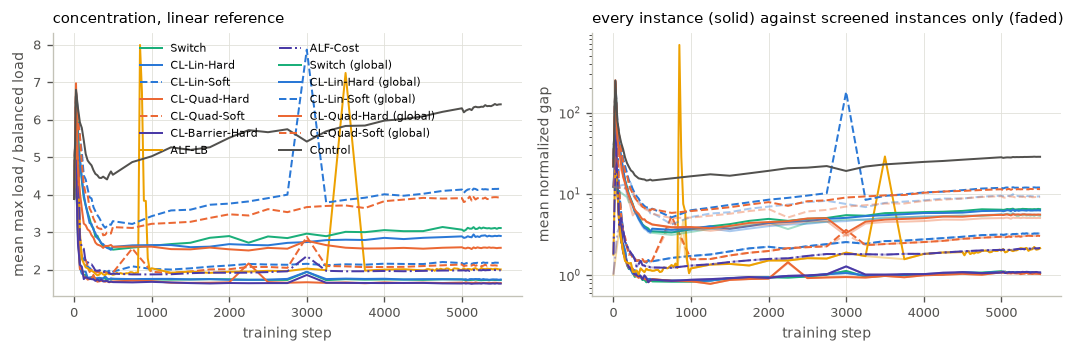

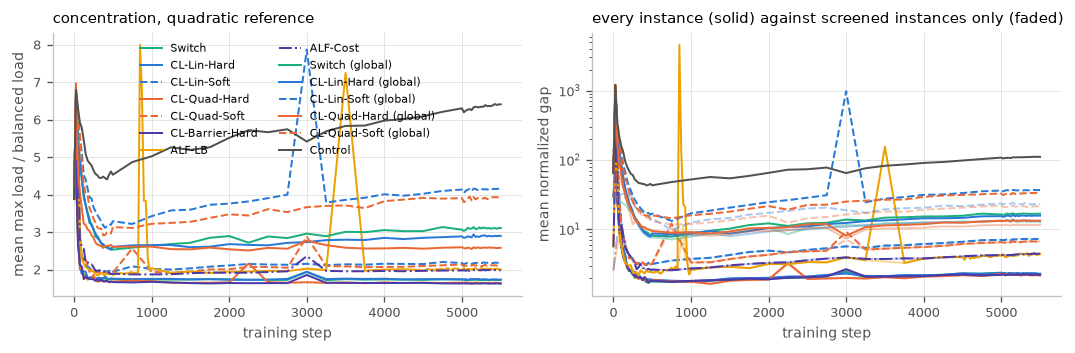

Every arm has the same 1680 late-window rows in the primary population (21 steps x 40 instances x 2 references), so the ranking is like for like.


In [19]:
# Rule 2's sensitivity check. Left: the concentration covariate. Right: the primary mean over every
# instance (solid) against the mean over screened instances only (faded). If the two curves
# separate, the screen was doing work, and the direction says which arms it was flattering.
def screen_panels(cost):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.0), sharex=True)
    rows = REF[~REF.stress & (REF.cost_family == cost)]
    for arm in ARMS_PRESENT:
        m = meta(arm)
        g = rows[rows.arm == arm]
        conc = g.groupby("step").max_load_over_balanced.mean()
        axes[0].plot(
            conc.index, conc.values, m["dash"], color=m["color"], label=m["label"], linewidth=1.2
        )
        every = g.groupby("step").gap_normalized.mean()
        screened = g[g.admissible].groupby("step").gap_normalized.mean()
        axes[1].plot(every.index, every.values, m["dash"], color=m["color"], linewidth=1.2)
        axes[1].plot(
            screened.index, screened.values, m["dash"], color=m["color"], linewidth=1.2, alpha=0.4
        )
    axes[0].set_title(f"concentration, {cost} reference", loc="left")
    axes[0].set_ylabel("mean max load / balanced load")
    axes[0].legend(loc="best", fontsize=6.5, ncol=2)
    axes[1].set_yscale("log")
    axes[1].set_title("every instance (solid) against screened instances only (faded)", loc="left")
    axes[1].set_ylabel("mean normalized gap")
    for ax in axes:
        ax.set_xlabel("training step")
    fig.tight_layout()
    plt.show()


for cost in COSTS:
    screen_panels(cost)

# Every arm is averaged over the same instances. While some grid is still running, an arm has fewer
# rows than the rest, and the missing ones are not random: they are the tail of one asset in the
# late window, exactly the window that is ranked.
keys = {
    a: set(
        map(tuple, LATE[(LATE.arm == a) & ~LATE.stress][["cost_family", "step", *INSTANCE]].values)
    )
    for a in ARMS_PRESENT
}
common = set.intersection(*keys.values())
short = {a: len(k) for a, k in keys.items() if len(k) != len(common)}
if not short:
    print(
        f"Every arm has the same {len(common)} late-window rows in the primary population "
        f"({len(LATE_STEPS)} steps x 40 instances x 2 references), so the ranking is like for like."
    )
else:
    print(
        f"rows every arm has: {len(common)}; arms with more: {short}. Rank on the common rows before reading the ranking table."
    )

---
## 8. Sensitivity to the reference coefficient λ (`tab_ex_lambda_sweep`)

The ranking prices congestion with λ = 1 in both reference costs, and any single λ is a choice. The λ sweep (decision 0057) scores arms again at the twelve values λ ∈ {0, 1/32, 1/16, 1/8, 3/16, 1/4, 3/8, 1/2, 1, 2, 4, 8}, on the 16 instances of the tail asset at step 5500. It answers one question: **does the order of the arms depend on λ?**

**How to read the table.** Each entry is an arm's mean normalized gap divided by λ.

- Once λ is large enough that the minimizer is exactly balanced, the minimizer stops changing and the normalizer stops changing with it. The gap then grows in proportion to λ, so gap / λ settles at a constant per arm.
- If that constant orders the arms the same way at every λ, the declared λ = 1 only rescales the gap and is not special.
- Only small λ bends the curve, which is why the grid is densest there.
- The table prints no bold. Whether the order of the arms is the same at every λ > 0 is printed in section 12.

**The λ = 0 endpoint** repeats the check of section 1 on the sweep: at zero price, the gap of every bias-free arm must be 0.

**Inputs.** The sweep is read from `assets/results/phi-gap/lambda-sweep/`, apart from the grid, so that its λ = 1 rows never meet the grid's. Until the sweep files are committed there, this section reads the gitignored working files `artifacts/phi_gap/*_sweep_step*.csv` and says so. Its λ = 1 rows are compared against the grid's as a consistency check.

**Extending it.** Sweep another arm with `scripts/run_phi_gap_grid.py` and the twelve `--lam` values (the frontier entry of `MANIFEST.csv` records the command), on the tail asset at step 5500, and put the CSV into the sweep folder. The table then gains one row per arm, in the order of the ranking.

The numbers the text quotes are collected in section 12: the λ = 0 check, the order, how close gap / λ is to its value at λ = 8, the affinity the minimizer gives up against the congestion it saves, and the unit-free share of the greedy gain it gives up.

In [20]:
# The lambda sweep: one table and the numbers the text quotes. Nothing is solved here.
LAMBDA_GRID = (
    0.0,
    0.03125,
    0.0625,
    0.125,
    0.1875,
    0.25,
    0.375,
    0.5,
    1.0,
    2.0,
    4.0,
    8.0,
)  # decision 0057 §1
LAMBDA_COLUMNS = (
    0.03125,
    0.125,
    0.5,
    1.0,
    8.0,
)  # the lambdas the table prints, under each reference
UNIT_TOKENS = 16_384  # n in gap_normalized = gap_per_token * n / normalizer, checked below


def shown_path(path):
    path = Path(path)
    return path.relative_to(ROOT) if path.is_relative_to(ROOT) else path


def load_sweep():
    """The sweep rows and whether they come from the committed folder, or (None, False) if there are none."""
    if SWEEP_DIR.is_dir() and any(SWEEP_DIR.glob("*.csv")):
        return load_grid(SWEEP_DIR), True
    if any(SWEEP_WORKING_DIR.glob(SWEEP_PATTERN)):
        print(
            f"NOTE: nothing committed under {shown_path(SWEEP_DIR)}/, so this reads the gitignored working files.\n"
            f"Commit them with: mkdir -p {shown_path(SWEEP_DIR)} && cp {shown_path(SWEEP_WORKING_DIR)}/{SWEEP_PATTERN} {shown_path(SWEEP_DIR)}/"
        )
        return load_grid(SWEEP_WORKING_DIR, SWEEP_PATTERN), False
    return None, False


SWEEP, SWEEP_COMMITTED = load_sweep()
if SWEEP is None:
    print(
        f"no lambda-sweep files under {shown_path(SWEEP_DIR)}/ or {shown_path(SWEEP_WORKING_DIR)}/{SWEEP_PATTERN}: "
        "section 8 skipped, tab_ex_lambda_sweep not written"
    )
else:
    sw = SWEEP[(SWEEP.status == "ok") & SWEEP.arm.isin(list(ARM_META))].copy()
    SWEEP_ARMS = [a for a in RANKING if a in set(sw.arm)]
    cell_key = ["step", *INSTANCE]
    cut = sw[cell_key].drop_duplicates()

    # A curve drawn through a hole misstates its shape: every arm needs every lambda of the grid at every
    # instance of the cut, under both references.
    outside = sorted(set(sw.lam) - set(LAMBDA_GRID))
    assert not outside, f"lambda outside the declared grid: {outside}"
    per_arm = sw.groupby("arm").size()
    expected = len(cut) * len(LAMBDA_GRID) * len(COSTS)
    holes = {a: sorted(set(LAMBDA_GRID) - set(sw[sw.arm == a].lam)) for a in SWEEP_ARMS}
    assert per_arm.loc[SWEEP_ARMS].eq(expected).all(), (
        f"incomplete sweep, {expected} rows expected per arm: {per_arm.to_dict()}; missing lambda: {holes}"
    )
    positive = sw[sw.lam > 0]
    assert np.allclose(
        positive.gap_per_token * UNIT_TOKENS / positive.normalizer,
        positive.gap_normalized,
        rtol=1e-9,
        atol=1e-9,
    ), "UNIT_TOKENS does not reproduce gap_normalized"
    print(
        f"sweep: {len(SWEEP_ARMS)} arms, {cut.asset.nunique()} asset(s), step(s) {sorted(int(v) for v in cut.step.unique())}, "
        f"{len(cut)} instances, {len(LAMBDA_GRID)} lambdas, {'committed' if SWEEP_COMMITTED else 'working files'}"
    )

    # The same dumps scored at lambda = 1 by the grid and by the sweep must agree.
    key = ["arm", "cost_family", *cell_key]
    both = sw[sw.lam == REFERENCE_LAM].merge(
        REF[key + ["gap_normalized"]], on=key, suffixes=("", "_grid")
    )
    agree = (
        (both.gap_normalized - both.gap_normalized_grid).abs().max() if len(both) else float("nan")
    )
    print(
        f"lambda = 1 against the grid: {len(both)} of {len(sw[sw.lam == REFERENCE_LAM])} rows matched, max |difference| {agree:.2e}"
    )

    # The lambda = 0 endpoint: a bias-free arm's realized routing is the minimizer.
    zero = sw[(sw.lam == 0) & ~sw.arm.isin(BIAS_ARMS)].gap_normalized.abs().max()
    print(f"lambda = 0, bias-free arms: max |gap_normalized| {zero:.1e}")

    # The statistic: the mean over the instances of the cut, divided by lambda.
    mean = positive.groupby(["arm", "cost_family", "lam"]).gap_normalized.mean()
    ratio = (mean / mean.index.get_level_values("lam")).rename("ratio")
    table = ratio.unstack(["cost_family", "lam"]).loc[SWEEP_ARMS]
    print("\nnormalized gap / lambda, mean over instances:")
    print(table.T.round(3).to_string())

    lam_columns = {
        f"{cost} {lam:g}": [sig3(table.loc[a, (cost, lam)]) for a in SWEEP_ARMS]
        for cost in COSTS
        for lam in LAMBDA_COLUMNS
    }
    write_rows(
        "tab_ex_lambda_sweep",
        render_rows("tab_ex_lambda_sweep", [flat_label(a) for a in SWEEP_ARMS], lam_columns),
    )

    # Is the order the same at every lambda > 0, and is it the order of the late-window ranking?
    order_at = {
        (cost, lam): mean.xs((cost, lam), level=("cost_family", "lam"))
        .loc[SWEEP_ARMS]
        .sort_values()
        .index.tolist()
        for cost in COSTS
        for lam in LAMBDA_GRID
        if lam > 0
    }
    ranking_order = {
        cost: sorted(SWEEP_ARMS, key=lambda a: gap_p.loc[a, ("mean", cost)]) for cost in COSTS
    }
    changed = [
        (cost, lam) for (cost, lam), order in order_at.items() if order != ranking_order[cost]
    ]

    # How close gap / lambda is to its value at the largest lambda.
    top = max(LAMBDA_GRID)
    long = ratio.reset_index()
    at_top = long[long.lam == top].set_index(["arm", "cost_family"]).ratio
    long["dev"] = long.ratio / at_top.loc[list(zip(long.arm, long.cost_family))].values - 1

    # What the minimizer does differently at lambda = 1, per assignment: the affinity it gives up and the
    # congestion it saves, relative to the realized routing. Within one affinity space only (rule 5).
    at1 = sw[sw.lam == REFERENCE_LAM].groupby(["cost_family", "arm"])
    give, save = -at1.affinity_shortfall.mean() / K, at1.congestion_excess.mean() / K

    # Unit-free: the affinity the minimizer gives up, as a share of what greedy top-K gains over the
    # round-robin profile, which is the normalizer at lambda = 0. Totals over the instances (ratio of sums).
    norm0 = sw[sw.lam == 0].set_index(["arm", "cost_family", *cell_key]).normalizer.rename("norm0")
    sh = positive.join(norm0, on=["arm", "cost_family", *cell_key])
    sh["given_up"] = -sh.affinity_shortfall * UNIT_TOKENS
    sums = sh.groupby(["arm", "cost_family", "lam"])[["given_up", "norm0"]].sum()
    share = (sums.given_up / sums.norm0).rename("share")

    S = "lambda sweep"
    note(
        S,
        "sweep",
        f"{', '.join(SWEEP_ARMS)}; {len(cut)} instances of {', '.join(sorted(cut.asset.unique()))} "
        f"at step(s) {', '.join(map(str, sorted(cut.step.unique())))}; {'committed' if SWEEP_COMMITTED else 'working files, not committed'}",
    )
    note(S, "lambda = 0, bias-free arms, max |gap_normalized|", f"{zero:.1e}")
    note(
        S,
        "same order at every lambda > 0 as the late-window ranking, both references",
        "yes" if not changed else f"no, differs at {changed}",
    )
    for floor in (0.5, 1.0):
        d = long[long.lam >= floor]
        worst = d.loc[d.dev.abs().idxmax()]
        note(
            S,
            f"gap / lambda for lambda >= {floor:g}, within ... of its lambda = {top:g} value",
            f"{100 * d.dev.abs().max():.1f} % ({worst.arm}, {worst.cost_family}, lambda {worst.lam:g})",
        )
    for cost in COSTS:
        note(
            S,
            f"lambda = 1, per assignment: affinity given up / congestion saved ({cost})",
            "; ".join(
                f"{a} {give.loc[(cost, a)]:.5f} / {save.loc[(cost, a)]:.4f} = {100 * give.loc[(cost, a)] / save.loc[(cost, a)]:.2f} %"
                for a in SWEEP_ARMS
            ),
        )
    for cost in COSTS:
        note(
            S,
            f"lambda = 1, share of the greedy gain the minimizer gives up ({cost})",
            ", ".join(f"{a} {share.loc[(a, cost, REFERENCE_LAM)]:.3f}" for a in SWEEP_ARMS),
        )
    late = share[share.index.get_level_values("lam") >= 0.5]
    note(
        S,
        "share of the greedy gain, range over lambda >= 1/2 (lin)",
        ", ".join(
            f"{a} {late.loc[(a, 'linear')].min():.3f} to {late.loc[(a, 'linear')].max():.3f}"
            for a in SWEEP_ARMS
        ),
    )

1152 rows from 3 file(s) in assets/results/phi-gap/lambda-sweep, 0 duplicate rows dropped:
  control_sweep_step5500.csv
  rosenthal_quadratic_hard_sweep_step5500.csv
  rosenthal_quadratic_soft_global_sweep_step5500.csv
sweep: 3 arms, 1 asset(s), step(s) [5500], 16 instances, 12 lambdas, committed
lambda = 1 against the grid: 96 of 96 rows matched, max |difference| 0.00e+00
lambda = 0, bias-free arms: max |gap_normalized| 2.8e-16

normalized gap / lambda, mean over instances:
arm                  rosenthal_quadratic_hard  rosenthal_quadratic_soft_global  control
cost_family lam                                                                        
linear      0.03125                     1.034                           10.042   17.088
            0.06250                     1.205                           12.110   23.308
            0.12500                     1.317                           13.510   28.135
            0.18750                     1.360                           14.056  

---
## 9. What separates the recipes: paired comparisons (`tab_ex_paired`)

Each pair differs in one factor only and is compared instance by instance, on the same tokens at the same layer. Every pair is reported in three ways:

- **Mean normalized gaps:** both arms' late-window means over the primary population.
- **Instances:** in how many of the 40 game instances arm A has the lower late-window mean.
- **Late steps:** at how many of the 21 late-window steps arm A's mean over the 40 instances is lower. This count is given for both references and for MaxVio.

The late-window steps come from one run per arm and are not independent. Their count shows whether an effect is stable over the anneal, not whether it is significant.

In [21]:
late_primary = LATE[~LATE.stress]


def pair(a, b):
    out = {}
    for cost in COSTS:
        wins, n, ma, mb = paired_instances(PRIMARY, a, b, cost)
        out[cost] = {
            "a": ma,
            "b": mb,
            "instances": wins,
            "steps": paired_steps(late_primary, a, b, cost),
        }
    x = PRIMARY[PRIMARY.cost_family == "linear"]
    m = x[x.arm == a].merge(x[x.arm == b], on=INSTANCE, suffixes=("_a", "_b"))
    out["maxvio"] = {
        "a": m.maxvio_a.mean(),
        "b": m.maxvio_b.mean(),
        "instances": int((m.maxvio_a < m.maxvio_b).sum()),
        "steps": paired_steps(late_primary, a, b, "linear", "maxvio"),
    }
    for cost in COSTS:
        y = PRIMARY[PRIMARY.cost_family == cost]
        r = y[y.arm == a].merge(y[y.arm == b], on=INSTANCE, suffixes=("_a", "_b"))
        out[f"raw {cost}"] = r.dphi_a.mean() / r.dphi_b.mean() - 1
    return out


def pair_label(arm):
    """The recipe name of arm_style.py, with "(global)" for a global-batch loss arm (the bias arms exist at
    that scope only), and without the dagger of the sigmoid arms."""
    return meta(arm)["table"].replace("$^{\\dagger}$", "") + (
        " (global)" if arm.endswith("_global") else ""
    )


BLOCKS = [
    (
        "Hard vs.\\ soft",
        [
            ("rosenthal_linear_hard", "rosenthal_linear_soft"),
            ("rosenthal_quadratic_hard", "rosenthal_quadratic_soft"),
            ("rosenthal_linear_hard_global", "rosenthal_linear_soft_global"),
            ("rosenthal_quadratic_hard_global", "rosenthal_quadratic_soft_global"),
        ],
    ),
    (
        "Micro vs.\\ global scope",
        [
            ("switch", "switch_global"),
            ("rosenthal_linear_hard", "rosenthal_linear_hard_global"),
            ("rosenthal_linear_soft", "rosenthal_linear_soft_global"),
            ("rosenthal_quadratic_hard", "rosenthal_quadratic_hard_global"),
            ("rosenthal_quadratic_soft", "rosenthal_quadratic_soft_global"),
        ],
    ),
    (
        "Steeper cost",
        steeper
        + [
            ("rosenthal_barrier_hard", "rosenthal_quadratic_hard"),
            ("rosenthal_barrier_hard", "rosenthal_linear_hard"),
        ],
    ),
    (
        "Same loss (\\cref{prop:switch-hard-linear})",
        [("switch", "rosenthal_linear_hard"), ("switch_global", "rosenthal_linear_hard_global")],
    ),
    ("Bias rule", [("rosenthal_price_barrier", "alflb")]),
]
PAIRS = {}
pair_rows = []
for block, (title, pairs) in enumerate(BLOCKS):
    if block:
        pair_rows.append("\\midrule")
    pair_rows.append(f"\\multicolumn{{5}}{{@{{}}l}}{{\\emph{{{title}}}}} \\\\")
    for a, b in pairs:
        r = PAIRS[(a, b)] = pair(a, b)
        digits = (
            4 if (a, b) == ("switch", "rosenthal_linear_hard") else 2
        )  # the identical-loss pair needs four
        lin, quad, mv_ = r["linear"], r["quadratic"], r["maxvio"]
        pair_rows.append(
            f"{pair_label(a)} & {pair_label(b)} & ${lin['a']:.{digits}f}$ / ${lin['b']:.{digits}f}$ & "
            f"${lin['instances']}$, ${quad['instances']}$ & ${lin['steps']}$, ${quad['steps']}$, ${mv_['steps']}$ \\\\"
        )
write_rows("tab_ex_paired", pair_rows)

print()
for (a, b), r in PAIRS.items():
    print(
        f"{a} vs {b}: gap lin {r['linear']['a']:.4f}/{r['linear']['b']:.4f} ({100 * (r['linear']['a'] / r['linear']['b'] - 1):+.1f} %), "
        f"quad {r['quadratic']['a']:.3f}/{r['quadratic']['b']:.3f} ({100 * (r['quadratic']['a'] / r['quadratic']['b'] - 1):+.1f} %); "
        f"instances {r['linear']['instances']}/{r['quadratic']['instances']}; steps {r['linear']['steps']}/{r['quadratic']['steps']}; "
        f"MaxVio {r['maxvio']['a']:.3f}/{r['maxvio']['b']:.3f}, lower in {r['maxvio']['instances']} instances, {r['maxvio']['steps']} steps"
    )

# The numbers the text quotes about the paired comparisons.
S = "paired comparisons"
hs = [PAIRS[p]["linear"]["b"] / PAIRS[p]["linear"]["a"] for p in BLOCKS[0][1]]
note(S, "hard vs soft, soft / hard (lin)", ", ".join(f"{v:.2f}" for v in hs))
mg = [PAIRS[p]["linear"]["b"] / PAIRS[p]["linear"]["a"] for p in BLOCKS[1][1]]
note(S, "micro vs global, global / micro (lin)", f"{min(mg):.2f} to {max(mg):.2f}")
for cost in COSTS:
    gains = [100 * (1 - PAIRS[p][cost]["a"] / PAIRS[p][cost]["b"]) for p in steeper]
    note(S, f"steeper cost lowers the gap by ({cost})", ", ".join(f"{g:.1f} %" for g in gains))
note(
    S,
    "steeper cost, instances with the lower gap (lin)",
    ", ".join(str(PAIRS[p]["linear"]["instances"]) for p in steeper),
)
sw = PAIRS[("switch", "rosenthal_linear_hard")]
note(
    S,
    "Switch vs linear hard, micro",
    f"{sw['linear']['a']:.4f} / {sw['linear']['b']:.4f}, Switch lower in {sw['linear']['instances']} of 40; "
    f"MaxVio {sw['maxvio']['a']:.4f} / {sw['maxvio']['b']:.4f} ({100 * (sw['maxvio']['a'] / sw['maxvio']['b'] - 1):+.1f} %), Switch lower at {sw['maxvio']['steps']}/{len(LATE_STEPS)} steps",
)
sg = PAIRS[("switch_global", "rosenthal_linear_hard_global")]
note(
    S,
    "Switch vs linear hard, global",
    f"gap {100 * (sg['linear']['a'] / sg['linear']['b'] - 1):+.1f} %, Switch lower at {sg['linear']['steps']}/{len(LATE_STEPS)} steps; "
    f"MaxVio {sg['maxvio']['a']:.3f} / {sg['maxvio']['b']:.3f} ({100 * (sg['maxvio']['a'] / sg['maxvio']['b'] - 1):+.1f} %)",
)
pb = PAIRS[("rosenthal_price_barrier", "alflb")]
note(
    S,
    "price barrier vs ALF-LB",
    f"gap {100 * (pb['linear']['a'] / pb['linear']['b'] - 1):+.3f} % (lin), {100 * (pb['quadratic']['a'] / pb['quadratic']['b'] - 1):+.3f} % (quad); "
    f"lower in {pb['linear']['instances']}/{pb['quadratic']['instances']} instances, at {pb['linear']['steps']}/{pb['quadratic']['steps']} steps; "
    f"raw gap {100 * pb['raw linear']:+.2f} % (lin), {100 * pb['raw quadratic']:+.2f} % (quad); "
    f"MaxVio {pb['maxvio']['a']:.4f} / {pb['maxvio']['b']:.4f}, lower in {pb['maxvio']['instances']} instances, {pb['maxvio']['steps']} steps",
)
best_global_loss = min(
    (a for a in RANKING if meta(a)["scope"] == "global" and a not in BIAS_ARMS),
    key=lambda a: gap_p.loc[a, ("mean", "linear")],
)
note(
    S,
    "bias arms vs the best global loss arm (lin)",
    ", ".join(f"{a} {gap_p.loc[a, ('mean', 'linear')]:.2f}" for a in sorted(BIAS_ARMS))
    + f" vs {best_global_loss} {gap_p.loc[best_global_loss, ('mean', 'linear')]:.2f}",
)

# The cost shape at the global-batch scope: the hard quadratic loss against the other two hard global loss arms.
S = "cost shape at the global scope"
for b in ("rosenthal_linear_hard_global", "switch_global"):
    r = PAIRS.get(("rosenthal_quadratic_hard_global", b)) or pair(
        "rosenthal_quadratic_hard_global", b
    )
    note(
        S,
        f"quadratic hard (global) vs {b}: gap lower by (lin / quad); instances; late steps; MaxVio",
        f"{100 * (1 - r['linear']['a'] / r['linear']['b']):.2f} % / {100 * (1 - r['quadratic']['a'] / r['quadratic']['b']):.2f} %; "
        f"lower in {r['linear']['instances']} / {r['quadratic']['instances']} of 40 instances; at {r['linear']['steps']} / {r['quadratic']['steps']} of {len(LATE_STEPS)} steps; "
        f"MaxVio {r['maxvio']['a']:.3f} / {r['maxvio']['b']:.3f}, lower in {r['maxvio']['instances']} instances",
    )

wrote tables/tab_ex_paired.tex, 27 lines

rosenthal_linear_hard vs rosenthal_linear_soft: gap lin 1.0857/3.2279 (-66.4 %), quad 2.316/7.160 (-67.7 %); instances 40/40; steps 21/21; MaxVio 0.737/1.174, lower in 35 instances, 21 steps
rosenthal_quadratic_hard vs rosenthal_quadratic_soft: gap lin 1.0560/3.0204 (-65.0 %), quad 2.202/6.590 (-66.6 %); instances 40/40; steps 21/21; MaxVio 0.645/1.110, lower in 37 instances, 21 steps
rosenthal_linear_hard_global vs rosenthal_linear_soft_global: gap lin 6.2636/11.9810 (-47.7 %), quad 15.635/36.455 (-57.1 %); instances 40/40; steps 21/21; MaxVio 1.888/3.135, lower in 40 instances, 21 steps
rosenthal_quadratic_hard_global vs rosenthal_quadratic_soft_global: gap lin 5.5738/11.4371 (-51.3 %), quad 13.269/32.859 (-59.6 %); instances 40/40; steps 21/21; MaxVio 1.579/2.898, lower in 40 instances, 21 steps
switch vs switch_global: gap lin 1.0852/6.5064 (-83.3 %), quad 2.293/16.672 (-86.2 %); instances 40/40; steps 21/21; MaxVio 0.721/2.096, lower in 39

---
## 10. What balance buys: expert computation time (`tab_ex_throughput`, `tab_ex_throughput_by_scope`, `fig_ex_throughput`)

In expert-parallel execution, the MoE layer exchanges tokens between devices before and after the experts. Every device waits for the most loaded one, so the most loaded device sets the pace.

**The model.** Assume one expert per device, dropless execution, and expert computation time proportional to the load. Then the expert computation of one layer takes `1 + MaxVio` times as long as under perfect balance. The 8 MoE layers run one after the other and have experts of the same size, so a forward pass takes

    F = mean over the 8 MoE layers of (1 + MaxVio_layer)

times as long as under perfect balance. F is computed per probe unit and step and averaged over the 5 units of the primary population and the 21 late-window steps. Arm A then needs `1 - F_A / F_R` less expert computation time than a reference arm R.

**Split by scope.** The probe units hold two micro batches, so the yardstick favours the micro-batch scope (section 2), and a saving of a micro-batch-scope arm over a global-batch-scope arm is partly built into the measurement. The table and the figure therefore compare arms within one scope only. Each block holds the arms of one scope, the control as the common baseline, and the saving against the control and against the Switch arm of the same scope. The two bias arms belong to the global-batch scope, the scope of the counts their bias is updated from (`arm_style.py`). A comparison across the scopes, such as against ALF-LB, stays in the text, which says that it crosses them.

This is an idealized estimate, not a measurement: the training runs used expert parallelism of size one, and the thesis lists the model's assumptions.

wrote tables/tab_ex_throughput_by_scope.tex, 18 lines
wrote tables/tab_ex_throughput.tex, 14 lines

                                  scope      F  F at 5500  F with stress unit  saving % vs switch  saving % vs switch_global  saving % vs alflb  saving % vs control
arm                                                                                                                                                                 
rosenthal_barrier_hard            micro  1.627      1.625               1.896                 5.5                       47.4               19.2                 74.3
rosenthal_quadratic_hard          micro  1.645      1.639               1.922                 4.4                       46.9               18.3                 74.0
switch                            micro  1.721      1.719               2.019                 0.0                       44.4               14.5                 72.8
rosenthal_linear_hard             micro  1.737      1.735               2.0

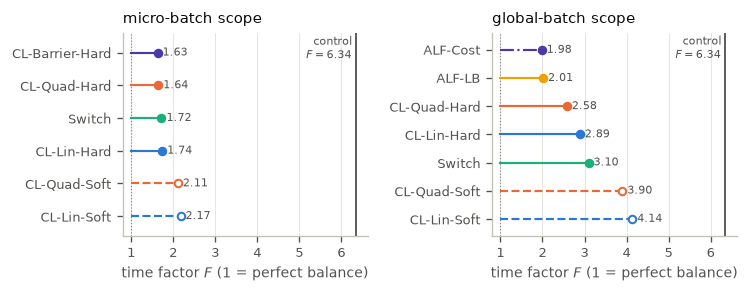

In [22]:
def time_factor(rows):
    """F per arm: the mean over the layers of max_e n_e / L per unit and step, then the mean over those."""
    return (
        rows.groupby(["arm", "asset", "unit", "step"])
        .max_load_over_balanced.mean()
        .groupby("arm")
        .mean()
    )


lin_late = LATE[LATE.cost_family == "linear"]
F = time_factor(lin_late[~lin_late.stress])
F_5500 = time_factor(REF[(REF.cost_family == "linear") & ~REF.stress & (REF.step == FINAL_STEP)])
F_all = time_factor(lin_late)
DAGGER = "$^{\\dagger}$"
# One block per balancing scope, each with its own Switch arm as the reference and the control as the baseline.
TP_BLOCKS = {
    "micro": ("Micro-batch scope", "switch"),
    "global": ("Global-batch scope", "switch_global"),
}
TP_ARMS = {
    scope: sorted([a for a in ARMS_PRESENT if meta(a)["scope"] == scope], key=F.get) + ["control"]
    for scope in TP_BLOCKS
}
assert (
    len(TP_ARMS["micro"]) == 7
    and len(TP_ARMS["global"]) == 8
    and set(BIAS_ARMS) <= set(TP_ARMS["global"])
)
tp_rows = []
for block, (scope, (title, switch_arm)) in enumerate(TP_BLOCKS.items()):
    arms = TP_ARMS[scope]
    if block:
        tp_rows.append("\\midrule")
    tp_rows.append(f"\\multicolumn{{4}}{{@{{}}l}}{{\\emph{{{title}}}}} \\\\")
    tp_columns = {
        "F": [f"${F[a]:.2f}$" for a in arms],
        "saving vs control": [pct(1 - F[a] / F["control"]) for a in arms],
        "saving vs Switch": [pct(1 - F[a] / F[switch_arm]) for a in arms],
    }
    tp_rows += render_rows(
        "tab_ex_throughput_by_scope",
        [meta(a)["table"].replace(DAGGER, "") for a in arms],
        tp_columns,
    )
write_rows("tab_ex_throughput_by_scope", tp_rows)

# The one-block table under its earlier name and layout (arm, F, saving vs Switch, ALF-LB and the control), so a
# thesis whose header still has those five columns keeps compiling. The split table above replaces it.
tp_order = F.sort_values().index
tp_columns = {"F": [f"${F[a]:.2f}$" for a in tp_order]}
tp_columns.update(
    {
        f"saving vs {ref}": [pct(1 - F[a] / F[ref]) for a in tp_order]
        for ref in ("switch", "alflb", "control")
    }
)
write_rows(
    "tab_ex_throughput",
    render_rows(
        "tab_ex_throughput", [flat_label(a).replace(DAGGER, "") for a in tp_order], tp_columns
    ),
)

saving = pd.DataFrame(
    {ref: 1 - F / F[ref] for ref in ("switch", "switch_global", "alflb", "control")}
)
print()
print(
    pd.DataFrame(
        {
            "scope": [meta(a)["scope"] for a in F.index],
            "F": F,
            "F at 5500": F_5500,
            "F with stress unit": F_all,
        },
        index=F.index,
    )
    .join((100 * saving).round(1).add_prefix("saving % vs "))
    .loc[F.sort_values().index]
    .round(3)
    .to_string()
)

S = "throughput"
lead_F = F.loc[LEAD_HARD]
note(S, "F of the leading four", f"{lead_F.min():.3f} to {lead_F.max():.3f}")
note(S, "F of the control", f"{F['control']:.3f}")
for scope, (title, switch_arm) in TP_BLOCKS.items():
    arms = [a for a in TP_ARMS[scope] if a != "control"]
    note(S, f"{title}: F per arm", ", ".join(f"{a} {F[a]:.3f}" for a in arms))
    note(
        S,
        f"{title}: saving vs control (%)",
        ", ".join(f"{a} {100 * saving.loc[a, 'control']:.1f}" for a in arms),
    )
    note(
        S,
        f"{title}: saving vs {switch_arm} (%)",
        ", ".join(f"{a} {100 * saving.loc[a, switch_arm]:.1f}" for a in arms),
    )
note(
    S,
    "saving vs Switch",
    f"quadratic hard {100 * saving.loc['rosenthal_quadratic_hard', 'switch']:.3f} %, softplus barrier {100 * saving.loc['rosenthal_barrier_hard', 'switch']:.3f} %",
)
note(
    S,
    "saving vs Switch (global)",
    f"quadratic hard (global) {100 * saving.loc['rosenthal_quadratic_hard_global', 'switch_global']:.3f} %, "
    f"ALF-LB {100 * saving.loc['alflb', 'switch_global']:.3f} %, price barrier {100 * saving.loc['rosenthal_price_barrier', 'switch_global']:.3f} %",
)
# Across the scopes: ALF-LB is a global-batch-scope arm scored on units of two micro batches.
note(
    S,
    "saving vs ALF-LB, across the scopes",
    f"Switch {100 * saving.loc['switch', 'alflb']:.3f} %, quadratic hard {100 * saving.loc['rosenthal_quadratic_hard', 'alflb']:.3f} %, price barrier {100 * saving.loc['rosenthal_price_barrier', 'alflb']:.3f} %",
)
groups = {
    "hard micro": LEAD_HARD,
    "soft micro": SOFT_MICRO,
    "bias": sorted(BIAS_ARMS),
    "hard global": HARD_GLOBAL,
    "soft global": SOFT_GLOBAL,
}
note(
    S,
    "control F and savings against it",
    f"F {F['control']:.3f}; "
    + "; ".join(
        f"{k} {100 * saving.loc[v, 'control'].min():.1f} to {100 * saving.loc[v, 'control'].max():.1f} %"
        for k, v in groups.items()
    ),
)
balanced = F.drop("control")
note(S, "worst / best balanced arm", f"{balanced.max() / balanced.min():.2f}")
note(
    S,
    "step 5500 vs late window, max |dF|",
    f"{(F_5500 - F).drop('control').abs().max():.4f} (balancing arms), {abs(F_5500 - F)['control']:.4f} (control)",
)
note(
    S,
    "with the stress unit",
    f"Switch {F_all['switch']:.3f}, ALF-LB {F_all['alflb']:.3f}; F rises for every arm: {bool((F_all > F).all())}; "
    f"leading order unchanged: {F_all.sort_values().index[:4].tolist() == F.sort_values().index[:4].tolist()}",
)
qh_sw = PAIRS.get(("rosenthal_quadratic_hard", "switch")) or pair(
    "rosenthal_quadratic_hard", "switch"
)
note(
    S,
    "MaxVio quadratic hard vs Switch",
    f"{qh_sw['maxvio']['a']:.4f} / {qh_sw['maxvio']['b']:.4f}, lower in {qh_sw['maxvio']['instances']} of {PRIMARY.groupby(INSTANCE).ngroups} instances and at {qh_sw['maxvio']['steps']}/{len(LATE_STEPS)} steps",
)
lead_mv = (
    PRIMARY[(PRIMARY.cost_family == "linear") & PRIMARY.arm.isin(LEAD_HARD)]
    .groupby("arm")
    .maxvio.mean()
)
note(
    S,
    "MaxVio of the four hard micro arms (% above balance)",
    f"{lead_mv.min():.3f} to {lead_mv.max():.3f}",
)


def throughput_figure():
    """F per arm in two panels by scope; the control as a reference line in both. Optional: the thesis may use it
    instead of the table."""
    fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.5), sharex=True)
    for ax, (scope, (title, _)) in zip(axes, TP_BLOCKS.items()):
        arms = [a for a in TP_ARMS[scope] if a != "control"][::-1]  # the most balanced arm on top
        ax.axvline(1.0, color=MUTED, lw=0.7, ls=":")
        ax.axvline(F["control"], color=meta("control")["color"], lw=1.1)
        ax.text(
            F["control"] - 0.08,
            len(arms) - 0.45,
            f"control\n$F = {F['control']:.2f}$",
            ha="right",
            va="top",
            fontsize=6.8,
            color=meta("control")["color"],
        )
        for y, arm in enumerate(arms):
            m = meta(arm)
            soft = "soft" in arm
            ax.plot([1.0, F[arm]], [y, y], m["dash"], color=m["color"], lw=1.3)
            ax.plot(
                F[arm],
                y,
                "o",
                ms=4.5,
                color=m["color"],
                mfc="white" if soft else m["color"],
                mew=1.2,
            )
            ax.text(F[arm] + 0.12, y, f"{F[arm]:.2f}", va="center", fontsize=6.8, color=INK_2)
        ax.set_yticks(range(len(arms)))
        ax.set_yticklabels([m_["table"].replace(DAGGER, "") for m_ in map(meta, arms)])
        ax.set_ylim(-0.6, len(arms) - 0.4)
        ax.set_title(title.lower(), loc="left", color=INK)
        ax.set_xlabel("time factor $F$ (1 = perfect balance)")
        ax.grid(axis="y", visible=False)
    axes[0].set_xlim(0.8, F["control"] + 0.3)
    fig.tight_layout(w_pad=1.5)
    save_figure(fig, "fig_ex_throughput")
    plt.show()


throughput_figure()

---
## 11. Downstream evaluation (`tab_ex_lm_eval`)

The scores come from `assets/results/eval/`: one row per arm, one column per task. Two details matter for reading them:

- **BLiMP** is the aggregate over its 67 subtasks that lm-eval reports in the `groups` block.
- **`FLAME-290M-1.3B`** is an external reference checkpoint, not one of our arms. It stays in the table but is excluded from every comparison, since it is a different model on a different token budget.

**Is a task's ranking real, or noise?** The range of a task's scores over the 14 arms is divided by the median standard error of one score.

- If the arms did not differ at all, this ratio would follow the studentized range of 14 means. On average it would be about 3.4, and it would exceed its 95 % quantile, about 4.7, in only 5 % of cases.
- This treats the scores as independent although all arms answer the same items, so it is conservative.
- The harness errors do not include the variation between seeds.

Clearing the threshold is not the same as meaning something. A column can clear it at a level where every arm is near its floor, which is what GSM8K does. Read the spread next to the chance level as well as next to the standard error.

In [23]:
REFERENCE_ARM = "FLAME-290M-1.3B"
# One metric per task, named rather than inferred. lm-eval reports several per task (acc and
# acc_norm on the multiple-choice ones, two extraction modes on gsm8k), so leaving the choice
# implicit would let different arms be scored on different quantities.
TASK_METRIC = {
    "arc_challenge": "acc,none",
    "arc_easy": "acc,none",
    "hellaswag": "acc,none",
    "piqa": "acc,none",
    "sciq": "acc,none",
    "winogrande": "acc,none",
    "openbookqa": "acc,none",
    "lambada_openai": "acc,none",
    "blimp": "acc,none",
    "gsm8k": "exact_match,strict-match",
    "wikitext": "word_perplexity,none",
}
LOWER_IS_BETTER = {"wikitext"}


def read_evals(eval_dir=EVAL_DIR):
    """Score table and its standard errors, one row per arm, with the grid's arm names."""
    scores, errors = {}, {}
    for path in sorted(eval_dir.glob("*.json")):
        doc = json.loads(path.read_text())
        arm, _, iteration = path.stem.partition("_iter_")
        arm = arm if arm == REFERENCE_ARM else arm.replace("-", "_")
        # One checkpoint per arm: the final step (FLAME-MoE's released step is 5473).
        expected = 5473 if arm == REFERENCE_ARM else FINAL_STEP
        if int(iteration) != expected:
            raise ValueError(f"{path.name}: step {int(iteration)}, expected {expected}")
        if arm in scores:
            raise ValueError(f"{path.name}: a second result for {arm}")
        # blimp's aggregate is in `groups`, not `results`, because it is a group of 67 subtasks.
        flat = dict(doc["results"])
        flat.update(doc.get("groups", {}))
        scores[arm] = {t: flat[t][m] for t, m in TASK_METRIC.items() if m in flat.get(t, {})}
        errors[arm] = {
            t: flat[t].get(m.replace(",", "_stderr,", 1))
            for t, m in TASK_METRIC.items()
            if m in flat.get(t, {})
        }
    # to_numeric, because lm-eval writes the string "N/A" where a task has no standard error.
    table = pd.DataFrame.from_dict(scores, orient="index").apply(pd.to_numeric, errors="coerce")
    stderr = pd.DataFrame.from_dict(errors, orient="index").apply(pd.to_numeric, errors="coerce")
    return table.reindex(columns=list(TASK_METRIC)), stderr.reindex(columns=list(TASK_METRIC))


evals, evals_stderr = read_evals()
arms_eval = evals.drop(index=REFERENCE_ARM)
errs_eval = evals_stderr.drop(index=REFERENCE_ARM)
print(f"{len(arms_eval)} arms and the reference, {len(evals.columns)} tasks")

# The noise threshold: the studentized range of k means. scipy has it; without scipy, a seeded
# Monte Carlo gives the same two numbers to about 0.01.
n_arms_eval = len(arms_eval)
rng = np.random.default_rng(0)
draws = rng.standard_normal((400_000, n_arms_eval))
expected_range = (draws.max(1) - draws.min(1)).mean()
try:
    from scipy.stats import studentized_range

    q95 = studentized_range.ppf(0.95, n_arms_eval, 1e6)
except ImportError:
    q95 = np.quantile(draws.max(1) - draws.min(1), 0.95)
judged = [t for t in TASK_METRIC if errs_eval[t].notna().any()]
separation = pd.DataFrame(
    {
        "best": [
            arms_eval[t].idxmin() if t in LOWER_IS_BETTER else arms_eval[t].idxmax() for t in judged
        ],
        "worst": [
            arms_eval[t].idxmax() if t in LOWER_IS_BETTER else arms_eval[t].idxmin() for t in judged
        ],
        "range / median stderr": [
            (arms_eval[t].max() - arms_eval[t].min()) / errs_eval[t].median() for t in judged
        ],
    },
    index=judged,
).sort_values("range / median stderr", ascending=False)
separation["separates"] = separation["range / median stderr"] > q95
print(
    f"noise threshold for {n_arms_eval} arms: expected range {expected_range:.2f}, 95 % quantile {q95:.2f}\n"
)
print(separation.round(2).to_string())

14 arms and the reference, 11 tasks


noise threshold for 14 arms: expected range 3.41, 95 % quantile 4.74

                                           best                     worst  range / median stderr  separates
blimp           rosenthal_quadratic_hard_global     rosenthal_linear_soft                  24.34       True
gsm8k                     rosenthal_linear_soft    rosenthal_barrier_hard                   5.54       True
lambada_openai  rosenthal_quadratic_soft_global                   control                   3.89      False
winogrande              rosenthal_price_barrier             switch_global                   2.58      False
sciq                                      alflb  rosenthal_quadratic_soft                   2.15      False
arc_easy                  rosenthal_linear_soft                   control                   2.06      False
arc_challenge                     switch_global  rosenthal_quadratic_soft                   1.89      False
piqa                              switch_global  rosenthal_quadrat

In [24]:
# The downstream-score table: accuracies in %, GSM8K exact match in %, WikiText word perplexity; then the reference
# model, then the separation ratio of each task.
EVAL_ORDER = [
    "control",
    "switch",
    "rosenthal_linear_hard",
    "rosenthal_linear_soft",
    "rosenthal_quadratic_hard",
    "rosenthal_quadratic_soft",
    "rosenthal_barrier_hard",
    "alflb",
    "rosenthal_price_barrier",
    "switch_global",
    "rosenthal_linear_hard_global",
    "rosenthal_linear_soft_global",
    "rosenthal_quadratic_hard_global",
    "rosenthal_quadratic_soft_global",
]
assert set(EVAL_ORDER) == set(arms_eval.index), set(arms_eval.index) ^ set(EVAL_ORDER)


def eval_cells(row):
    return " & ".join(eval_cell(t, row[t]) for t in TASK_METRIC)


def eval_cell(task, value):
    return f"{value:.2f}" if task == "wikitext" else f"{100 * value:.1f}"


# the 14 arms, with the best score per task in bold (BEST in section 1); the reference model is not ranked
lm_columns = {t: [eval_cell(t, evals.loc[a, t]) for a in EVAL_ORDER] for t in TASK_METRIC}
lm_rows = render_rows(
    "tab_ex_lm_eval", [flat_label(a).replace(DAGGER, "") for a in EVAL_ORDER], lm_columns
)
lm_rows += [
    "\\midrule",
    f"FLAME-MoE (reference) & {eval_cells(evals.loc[REFERENCE_ARM])} \\\\",
    "\\midrule",
]
ratio_of = separation["range / median stderr"]
lm_rows.append(
    "Range / std.\\ error & "
    + " & ".join(f"{ratio_of[t]:.1f}" if t in ratio_of.index else "---" for t in TASK_METRIC)
    + " \\\\"
)
write_rows("tab_ex_lm_eval", lm_rows)

S = "downstream"
note(
    S,
    "noise threshold",
    f"expected range {expected_range:.2f}, 95 % quantile {q95:.2f} ({n_arms_eval} arms)",
)
quiet = separation[~separation.separates & (separation.index != "lambada_openai")][
    "range / median stderr"
]
note(
    S,
    "tasks below the threshold (without LAMBADA)",
    f"{len(quiet)} tasks, {quiet.min():.2f} to {quiet.max():.2f}; LAMBADA {ratio_of['lambada_openai']:.2f}",
)
note(
    S,
    "tasks above the threshold",
    ", ".join(f"{t} {ratio_of[t]:.1f}" for t in separation.index[separation.separates]),
)
note(S, "GSM8K range", f"{100 * arms_eval.gsm8k.min():.2f} to {100 * arms_eval.gsm8k.max():.2f} %")
blimp = (100 * arms_eval.blimp).sort_values(ascending=False)
note(
    S,
    "BLiMP best, second, worst",
    f"{blimp.index[0]} {blimp.iloc[0]:.1f}, {blimp.index[1]} {blimp.iloc[1]:.1f}, {blimp.index[-1]} {blimp.iloc[-1]:.1f}",
)
rank_corr = (
    pd.Series(arms_eval.blimp)
    .rank()
    .corr(-gap_p[("mean", "linear")].reindex(arms_eval.index).rank())
)
note(
    S,
    "Spearman rank correlation of BLiMP with the gap ranking (better = higher)",
    f"{rank_corr:.2f}",
)
global_loss = [a for a in arms_eval.index if a.endswith("_global")]
micro = [a for a in arms_eval.index if meta(a)["scope"] == "micro"]
note(
    S,
    "WikiText perplexity",
    f"global loss arms {', '.join(f'{a} {arms_eval.wikitext[a]:.2f}' for a in sorted(global_loss, key=lambda a: arms_eval.wikitext[a]))}; "
    f"micro arms {arms_eval.wikitext[micro].min():.2f} to {arms_eval.wikitext[micro].max():.2f}; "
    f"bias arms {', '.join(f'{a} {arms_eval.wikitext[a]:.2f}' for a in sorted(BIAS_ARMS))}",
)
# The training loss of section 2 against WikiText, and the global loss arms that beat every micro arm on both.
note(
    S,
    "Spearman, training loss (steps 5401-5500) vs WikiText perplexity, 14 arms",
    f"{spearman(TRAIN_LOSS, arms_eval.wikitext):.4f}",
)
# The same for every task, and within the groups of one scope. For an accuracy, a negative value means that a lower
# training loss goes with a higher score; for WikiText, a positive one means a lower loss goes with a lower perplexity.
note(
    S,
    "Spearman, training loss vs each task, 14 arms",
    ", ".join(f"{t} {spearman(TRAIN_LOSS, arms_eval[t]):+.2f}" for t in TASK_METRIC),
)
for name, group in [("6 micro arms", MICRO_ARMS), ("5 global loss arms", GLOBAL_LOSS_ARMS)]:
    note(
        S,
        f"Spearman, training loss vs each task, {name}",
        ", ".join(
            f"{t} {spearman(TRAIN_LOSS[group], arms_eval[t].reindex(group)):+.2f}"
            for t in TASK_METRIC
        ),
    )
both = [
    a
    for a in GLOBAL_LOSS_ARMS
    if TRAIN_LOSS[a] < TRAIN_LOSS[MICRO_ARMS].min()
    and arms_eval.wikitext[a] < arms_eval.wikitext[MICRO_ARMS].min()
]
note(
    S,
    "global loss arms below every micro arm in training loss and in WikiText",
    f"{len(both)} of 5; training loss {TRAIN_LOSS[both].min():.4f} to {TRAIN_LOSS[both].max():.4f}, WikiText {arms_eval.wikitext[both].min():.2f} to {arms_eval.wikitext[both].max():.2f}; "
    f"micro arms: training loss {TRAIN_LOSS[MICRO_ARMS].min():.4f} to {TRAIN_LOSS[MICRO_ARMS].max():.4f}, WikiText {arms_eval.wikitext[MICRO_ARMS].min():.2f} to {arms_eval.wikitext[MICRO_ARMS].max():.2f}",
)

# What the tighter balance of the hard quadratic loss at the global scope comes with: its training loss and WikiText
# perplexity against the other global loss arms, the micro arms and the difference between the global twins.
S = "cost shape at the global scope"
qg = "rosenthal_quadratic_hard_global"
others = [a for a in GLOBAL_LOSS_ARMS if a != qg]
note(
    S,
    "quadratic hard (global): training loss, rank among the 5 global loss arms (1 = lowest), WikiText, rank",
    f"{TRAIN_LOSS[qg]:.4f}, {int(TRAIN_LOSS[GLOBAL_LOSS_ARMS].rank()[qg])}; {arms_eval.wikitext[qg]:.2f}, {int(arms_eval.wikitext[GLOBAL_LOSS_ARMS].rank()[qg])}",
)
note(
    S,
    "quadratic hard (global) minus linear hard (global) and minus Switch (global), training loss",
    f"{TRAIN_LOSS[qg] - TRAIN_LOSS['rosenthal_linear_hard_global']:+.4f}, {TRAIN_LOSS[qg] - TRAIN_LOSS['switch_global']:+.4f} nats; "
    f"global twins differ by {abs(TRAIN_LOSS['switch_global'] - TRAIN_LOSS['rosenthal_linear_hard_global']):.4f}",
)
note(
    S,
    "quadratic hard (global) minus linear hard (global) and minus Switch (global), WikiText perplexity",
    f"{arms_eval.wikitext[qg] - arms_eval.wikitext['rosenthal_linear_hard_global']:+.2f}, {arms_eval.wikitext[qg] - arms_eval.wikitext['switch_global']:+.2f}; "
    f"global twins differ by {abs(arms_eval.wikitext['switch_global'] - arms_eval.wikitext['rosenthal_linear_hard_global']):.2f}",
)
note(
    S,
    "quadratic hard (global) inside the micro arms' range, training loss and WikiText",
    f"{TRAIN_LOSS[MICRO_ARMS].min() <= TRAIN_LOSS[qg] <= TRAIN_LOSS[MICRO_ARMS].max()}, "
    f"{arms_eval.wikitext[MICRO_ARMS].min() <= arms_eval.wikitext[qg] <= arms_eval.wikitext[MICRO_ARMS].max()}",
)


def highlight_best(frame):
    """Bold the best value in each column, lowest for perplexity and highest elsewhere."""

    def mark(col):
        target = col.min() if col.name in LOWER_IS_BETTER else col.max()
        return ["font-weight: bold" if v == target else "" for v in col]

    return frame.style.apply(mark).format("{:.4f}")


# The styled table needs jinja2; without it, show the plain one.
try:
    display_table = highlight_best(evals.loc[EVAL_ORDER + [REFERENCE_ARM]])
    display_table.to_html()
except ImportError:
    display_table = evals.loc[EVAL_ORDER + [REFERENCE_ARM]].round(4)
display_table

wrote tables/tab_ex_lm_eval.tex, 18 lines


,arc_challenge,arc_easy,hellaswag,piqa,sciq,winogrande,openbookqa,lambada_openai,blimp,gsm8k,wikitext
control,0.2474,0.5362,0.3054,0.6561,0.8100,0.5130,0.2000,0.2804,0.7849,0.0030,35.3027
switch,0.2500,0.5530,0.3078,0.6572,0.8130,0.5193,0.1880,0.2915,0.7860,0.0129,34.8900
rosenthal_linear_hard,0.2491,0.5442,0.3063,0.6540,0.8130,0.5280,0.1920,0.2911,0.7812,0.0129,35.0746
rosenthal_linear_soft,0.2509,0.5572,0.3096,0.6621,0.8210,0.5146,0.1820,0.3006,0.7591,0.0152,34.6002
rosenthal_quadratic_hard,0.2423,0.5463,0.3071,0.6540,0.8220,0.5201,0.1740,0.3000,0.7726,0.0091,34.9222
rosenthal_quadratic_soft,0.2338,0.5560,0.3074,0.6523,0.8060,0.5241,0.1920,0.2959,0.7804,0.0068,35.3469
rosenthal_barrier_hard,0.2355,0.5484,0.3073,0.6556,0.8210,0.5075,0.1940,0.2917,0.7888,0.0023,35.2793
alflb,0.2483,0.5446,0.3089,0.6697,0.8320,0.5272,0.1880,0.2872,0.7911,0.0076,35.2628
rosenthal_price_barrier,0.2500,0.5547,0.3091,0.6627,0.8240,0.5312,0.2000,0.2855,0.7741,0.0061,35.0520
switch_global,0.2577,0.5543,0.3125,0.6725,0.8210,0.4949,0.2000,0.2909,0.7815,0.0061,34.0145


---
## 12. Every number the text quotes

The tables are written above. This section collects the numbers that the running text quotes, so they can be checked against it in one pass. They are grouped by the topic of the section above that computes them and printed in the order of this notebook, with more decimals than the thesis uses. In a few places the thesis quotes a bound rather than the value.

**How the percentages are formed.** A relative difference always names its base, the value that counts as 100 %:

- **"x % below B"** is `100 * (1 - A / B)`, and **"A / B (±x %)"** is `100 * (A / B - 1)`, both relative to arm B. The values are normalized gaps, which have no unit, so these are relative differences, not percentage points.
- **"spread"** of a group is `100 * (max / min - 1)`, relative to its lowest member.
- **"saving vs R"** in the throughput section is `100 * (1 - F_A / F_R)`, relative to the reference arm R.
- **"deviation"** of a cut, or of gap / λ, is relative to the late-window mean, or to the value at λ = 8.
- **A share** is a part divided by its whole, e.g. the affinity shortfall divided by the gap.

In [25]:
# In the order of this notebook: NUMBERS keeps the order in which its topics were first noted.
for section in NUMBERS:
    print(f"[{section}]")
    for name, value in NUMBERS[section].items():
        print(f"  {name}: {value}")
    print()
print(
    f"written to {OUT_DIR.relative_to(ROOT)}/",
    f"and to {THESIS_DIR}/"
    if THESIS_DIR
    else "(set THESIS_DIR to copy them into the thesis as well)",
)
for name in WRITTEN:
    print(" ", name)

[ranking]
  leading four, linear: 1.056 to 1.090, spread 3.23 %
  leading four, quadratic: 2.202 to 2.316, spread 5.15 %
  softplus barrier, rank linear / quadratic: 4 / 2
  bias arms / mean of the leading four (lin): alflb 1.92, rosenthal_price_barrier 1.95
  price barrier vs ALF-LB, linear: +1.40 %
  price barrier vs ALF-LB, quadratic: +1.65 %
  control, linear: 28.47 = 27.0 x the first arm
  order the same under both references from the bias arms on: True
  quadratic order of the leading four: rosenthal_quadratic_hard, rosenthal_barrier_hard, switch, rosenthal_linear_hard

[training loss]
  source: W&B export for 14 arms; rosenthal_price_barrier: W&B export, step 4000 from the log moe_train_3345837.log + moe_train_3355934.log
  export against the training logs: 9 arms (rosenthal_quadratic_soft_global, rosenthal_linear_hard_global, rosenthal_quadratic_hard_global, switch, rosenthal_linear_soft, rosenthal_linear_soft_global, switch_global, rosenthal_barrier_hard, rosenthal_price_barri